# FitPulse – Personalized Fitness and Activity Analytics Using Big Data

**Faculty demonstration notebook.** Every number in this notebook is computed live from the
project's actual dataset by the project's actual code (`data/prepare_raw_dataset.py`,
`etl/spark_etl.py`) followed by Apache Spark / Spark MLlib. Nothing is typed in by hand —
re-running the notebook top-to-bottom reproduces every value (fixed seed = 42).

> **How to read this notebook:** each section has (1) a short explanation, (2) code,
> (3) the actual output, (4) an interpretation. All result tables are also saved to
> `faculty_evidence/`.

## 1. Project Overview

FitPulse turns daily wearable fitness data into personalized insights. The pipeline that is
**actually implemented in this repository**:

```
Kaggle FitLife dataset (687,701 rows / 3,000 participants)
        │  data/prepare_raw_dataset.py   (pandas, one-time: sample 437 users, clean, unit conversions)
        ▼
data/raw/fitpulse_raw.csv               Bronze layer – raw landing zone
        │  etl/spark_etl.py              (Apache Spark: cleaning, window/lag features, per-user goals)
        ▼
data/processed/fitpulse_silver/         Silver layer – Parquet, partitioned by month
        │  this notebook                 (Spark MLlib: Random Forest + K-Means)
        ▼
Personalized insights                   models/*.py, models/recommendation_engine.py
        ▼
Dashboard                               dashboard/app.py (Streamlit)
```

**What is and isn't implemented (verified by inspecting the repository):**

| Component | Status in this repo |
|---|---|
| Raw preprocessing | ✅ `data/prepare_raw_dataset.py` (pandas) |
| Apache Spark / PySpark ETL | ✅ `etl/spark_etl.py`, `etl/spark_benchmarks.py` – runs in Spark **local mode** (`local[*]`) |
| Distributed storage | ✅ Single-node Hadoop HDFS 3.4.1 (NameNode + DataNode, replication 1) holds Bronze and Silver; verified in **§11**. Sections 1-10 were executed on local Parquet (the explicit fallback) before HDFS existed. No fault tolerance (one node) |
| Random Forest | ✅ `models/train_goal_achievement.py` (scikit-learn); this notebook re-implements it in **Spark MLlib** (§6); the REPORT's different same-day experiment is implemented in `models/spark_report_classification.py` (§13) |
| K-Means clustering | ✅ added in this notebook (§7, user-days); the REPORT's user-level version is `models/spark_report_kmeans.py` (§13) |
| Linear Regression (calories) | ✅ `models/train_calorie_regression.py`, Spark MLlib (§12) |
| 70/15/15 split | ❌ the existing script uses a chronological train/test split – **a 70/15/15 split is added in this notebook** (§5), and the original chronological split is reproduced as a robustness check (§6.12) |
| Dashboard | ✅ **Power BI** (`powerbi/FitPulse_PowerBI_Dashboard.pbix`, built and checked in Power BI Desktop; imports CSV, not HDFS) is the primary dashboard (§14). The earlier Streamlit app (`dashboard/app.py`) is legacy/optional |

### Environment setup

Configures Java/Spark for this machine. On this Windows laptop a portable JDK 17 and the
Hadoop Windows binaries (`winutils.exe`, `hadoop.dll`) live in `../tools/` (Spark 4 needs
JDK 17/21; the system JDK 23/25 is too new for Hadoop's security APIs).

In [1]:
import os, sys, re, json, time, shutil, hashlib, subprocess, importlib.util, contextlib, io, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless tqdm notice from kagglehub
from pathlib import Path

PROJECT_ROOT = Path.cwd()
assert (PROJECT_ROOT / "etl" / "spark_etl.py").exists(), "Start Jupyter from inside the FitPulse/ folder"

TOOLS = PROJECT_ROOT.parent / "tools"          # local JDK 17 + Hadoop winutils for this machine
if (TOOLS / "jdk17").exists():
    os.environ["JAVA_HOME"] = str(TOOLS / "jdk17")
if (TOOLS / "hadoop").exists():
    os.environ["HADOOP_HOME"] = str(TOOLS / "hadoop")
for var in ("HADOOP_HOME", "JAVA_HOME"):
    if var in os.environ:
        os.environ["PATH"] = str(Path(os.environ[var]) / "bin") + os.pathsep + os.environ["PATH"]
if (TOOLS / "tmp").exists():                   # keep Spark temp files off the (full) C: drive
    os.environ["TMP"] = os.environ["TEMP"] = str(TOOLS / "tmp")
os.environ.setdefault("KAGGLEHUB_CACHE", str(TOOLS / "kagglehub"))
os.environ["PYSPARK_PYTHON"] = os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["PYTHONIOENCODING"] = "utf-8"

EVIDENCE = PROJECT_ROOT / "faculty_evidence"
EVIDENCE.mkdir(exist_ok=True)
SEED = 42                                       # one seed for every random operation in this notebook

java = shutil.which("java")
java_version = subprocess.run([java, "-version"], capture_output=True, text=True).stderr.splitlines()[0]
print("Project root :", PROJECT_ROOT)
print("Python       :", sys.version.split()[0], "-", sys.executable)
print("Java         :", java_version)
print("JAVA_HOME    :", os.environ.get("JAVA_HOME"))
print("HADOOP_HOME  :", os.environ.get("HADOOP_HOME"))

Project root : D:\bigdata\fitpulsee\FitPulse
Python       : 3.12.10 - D:\bigdata\fitpulsee\.venv\Scripts\python.exe
Java         : openjdk version "17.0.20.1" 2026-08-18
JAVA_HOME    : D:\bigdata\fitpulsee\tools\jdk17
HADOOP_HOME  : D:\bigdata\fitpulsee\tools\hadoop


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

# Chart styling: thin marks, recessive grid, one blue for single-series charts
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.axisbelow": True,
})


def run_project_script(rel_path, log_name):
    # Runs one of the project's own pipeline scripts exactly as `python <script>` would,
    # prints its real stdout, and saves it to faculty_evidence/ as a log.
    t0 = time.time()
    proc = subprocess.run([sys.executable, rel_path], cwd=PROJECT_ROOT, capture_output=True,
                          text=True, encoding="utf-8", errors="replace")
    elapsed = time.time() - t0
    log = f"$ python {rel_path}\nexit code: {proc.returncode}   elapsed: {elapsed:.1f}s\n\n{proc.stdout}"
    (EVIDENCE / log_name).write_text(log, encoding="utf-8")
    print(log)
    if proc.returncode != 0:
        print(proc.stderr[-4000:])
        raise RuntimeError(f"{rel_path} failed")


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

## 2. Dataset Description

### 2.1 Dataset Source

* **Original source:** Kaggle – [`jijagallery/fitlife-health-and-fitness-tracking-dataset`](https://www.kaggle.com/datasets/jijagallery/fitlife-health-and-fitness-tracking-dataset)
  (version 1). It is a *wearable-style* health & fitness tracking dataset (one row per participant-day).
  Important honesty note: it is a public, research/teaching dataset, not exported from our own devices.
* **Raw preparation:** `data/prepare_raw_dataset.py` samples **437 participants** (seed 42) and keeps each
  one's full yearly time series, then reshapes the columns into a wearable-export schema.
* **Bronze layer:** `data/raw/fitpulse_raw.csv` – the input to Spark.

Below, the project's two pipeline scripts are **actually executed** (not simulated). The SHA-256 hash
of the Bronze file before and after proves the raw preparation is exactly reproducible.

In [3]:
# Step 0 - raw preparation (project script, unchanged logic)
RAW_PATH = "data/raw/fitpulse_raw.csv"
hash_before = sha256(RAW_PATH) if Path(RAW_PATH).exists() else None
run_project_script("data/prepare_raw_dataset.py", "log_prepare_raw_dataset.txt")
hash_after = sha256(RAW_PATH)
print("SHA-256 before:", hash_before)
print("SHA-256 after :", hash_after)
print("Bronze file reproduced byte-for-byte:", hash_before == hash_after)

$ python data/prepare_raw_dataset.py
exit code: 0   elapsed: 6.9s

Source: D:\bigdata\fitpulsee\tools\kagglehub\datasets\jijagallery\fitlife-health-and-fitness-tracking-dataset\versions\1\health_fitness_dataset.csv
Wrote data/raw/fitpulse_raw.csv: 100,122 rows, 23 columns, 437 users
Date range: 2024-01-01 to 2024-12-25

SHA-256 before: 9f186fb21adb6fb38fc00781e51b11ce802a5d901eae54318e781bde94d69606
SHA-256 after : 9f186fb21adb6fb38fc00781e51b11ce802a5d901eae54318e781bde94d69606
Bronze file reproduced byte-for-byte: True


In [4]:
# Step 1 - Spark ETL, Bronze -> Silver (project script, unchanged)
SILVER_PATH = "data/processed/fitpulse_silver"
run_project_script("etl/spark_etl.py", "log_spark_etl.txt")

$ python etl/spark_etl.py
exit code: 0   elapsed: 27.5s

[1/7] Reading Bronze layer (raw CSV) into a Spark DataFrame
[2/7] Cleaning & validation
[3/7] Feature engineering — day-of-week, rest-day flag, month partition key
[4/7] Rolling averages & lag features (Spark Window functions)
[5/7] Personalized goals — per-user MapReduce aggregation
[6/7] Deriving goal_achieved / calorie_goal_achieved labels
[7/7] Writing Silver layer as partitioned Parquet (HDFS-style storage)

--- Summary ---
Bronze rows read      : 100,122
Rows after cleaning   : 100,122 (0 dropped)
Silver rows written   : 100,122
Silver columns        : 39
Users                 : 437
Written to            : data/processed/fitpulse_silver/ (partitioned by month)
SUCCESS: The process with PID 16568 (child process of PID 14676) has been terminated.
SUCCESS: The process with PID 14676 (child process of PID 22804) has been terminated.
SUCCESS: The process with PID 22804 (child process of PID 25100) has been terminated.



**Interpretation:** both pipeline stages ran successfully on this machine. The Spark ETL read the
Bronze CSV, applied its cleaning rules, engineered the features, and wrote the Silver layer as
Parquet partitioned by month. Everything below reads those real outputs.

Now we start this notebook's own Spark session (the ETL script stopped its own session when it finished).

In [5]:
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T

builder = (
    SparkSession.builder
    .appName("FitPulse-Faculty-Demo")
    .master("local[*]")                                   # same execution mode as etl/spark_etl.py
    .config("spark.sql.shuffle.partitions", "8")          # same setting as etl/spark_etl.py
    .config("spark.driver.memory", "2g")
    .config("spark.driver.host", "127.0.0.1")
)
if (TOOLS / "tmp").exists():
    builder = builder.config("spark.local.dir", str(TOOLS / "tmp"))
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version, "| master:", spark.sparkContext.master,
      "| default parallelism:", spark.sparkContext.defaultParallelism)

Spark version: 4.0.1 | master: local[*] | default parallelism: 12


In [6]:
# The original Kaggle file - located with the project's own resolve_source() function
spec = importlib.util.spec_from_file_location("prepare_raw_dataset", PROJECT_ROOT / "data" / "prepare_raw_dataset.py")
prepare_raw_dataset = importlib.util.module_from_spec(spec)
spec.loader.exec_module(prepare_raw_dataset)
SOURCE_PATH = prepare_raw_dataset.resolve_source()

source = spark.read.csv(SOURCE_PATH, header=True, inferSchema=True)
bronze = spark.read.csv(RAW_PATH, header=True, inferSchema=True)      # identical call to spark_etl.py
silver = spark.read.parquet(SILVER_PATH)

print("Kaggle source file :", SOURCE_PATH)
print("Bronze file        :", RAW_PATH)
print("Silver dataset     :", SILVER_PATH)

Kaggle source file : D:\bigdata\fitpulsee\tools\kagglehub\datasets\jijagallery\fitlife-health-and-fitness-tracking-dataset\versions\1\health_fitness_dataset.csv
Bronze file        : data/raw/fitpulse_raw.csv
Silver dataset     : data/processed/fitpulse_silver


### 2.2 Dataset Dimensions

In [7]:
def dims(df, name):
    users_col = "participant_id" if "participant_id" in df.columns else "user_id"
    agg = df.agg(F.countDistinct(users_col).alias("users"), F.min("date").alias("first"),
                 F.max("date").alias("last")).first()
    return {"Layer": name, "Rows": df.count(), "Columns": len(df.columns), "Users": agg["users"],
            "First date": str(agg["first"])[:10], "Last date": str(agg["last"])[:10]}

dataset_summary = pd.DataFrame([dims(source, "Kaggle source"), dims(bronze, "Bronze (raw CSV)"),
                                dims(silver, "Silver (Spark output)")])
dataset_summary.to_csv(EVIDENCE / "dataset_summary.csv", index=False)
display(dataset_summary)

,Layer,Rows,Columns,Users,First date,Last date
0,Kaggle source,687701,22,3000,2024-01-01,2024-12-25
1,Bronze (raw CSV),100122,23,437,2024-01-01,2024-12-25
2,Silver (Spark output),100122,39,437,2024-01-01,2024-12-25


In [8]:
# Equivalent direct calls on the Bronze DataFrame
print("bronze.count()      =", bronze.count())
print("len(bronze.columns) =", len(bronze.columns))
print("bronze.columns      =", bronze.columns)
print()
print("silver.count()      =", silver.count())
print("len(silver.columns) =", len(silver.columns))
print("Columns added by Spark ETL:", [c for c in silver.columns if c not in bronze.columns])

bronze.count()      = 100122
len(bronze.columns) = 23
bronze.columns      = ['user_id', 'date', 'steps', 'calories_burned', 'distance_km', 'active_minutes', 'sedentary_minutes', 'resting_heart_rate', 'avg_heart_rate', 'max_heart_rate', 'sleep_minutes', 'sleep_quality_score', 'activity_type', 'intensity', 'age', 'gender', 'height_cm', 'weight_kg', 'bmi', 'health_condition', 'smoking_status', 'stress_level', 'hydration_level']



silver.count()      = 100122
len(silver.columns) = 39
Columns added by Spark ETL: ['day_of_week', 'is_rest_day', 'steps_lag1', 'steps_lag2', 'steps_lag7', 'calories_lag1', 'sleep_quality_lag1', 'steps_roll7_avg', 'calories_roll7_avg', 'active_minutes_roll7_avg', 'resting_hr_roll7_avg', 'daily_step_goal', 'daily_calorie_goal', 'goal_achieved', 'calorie_goal_achieved', 'month']


**Interpretation:** the project works on a 437-user subset of the Kaggle dataset, keeping each user's
complete year of daily records so that per-user time-series features (lags, rolling averages) are
meaningful. The Spark ETL keeps every Bronze row and adds the engineered columns listed above.

### 2.3 Dataset Schema

In [9]:
print("BRONZE schema (raw CSV, types inferred by Spark):")
bronze.printSchema()

BRONZE schema (raw CSV, types inferred by Spark):
root
 |-- user_id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- steps: integer (nullable = true)
 |-- calories_burned: double (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- active_minutes: integer (nullable = true)
 |-- sedentary_minutes: integer (nullable = true)
 |-- resting_heart_rate: double (nullable = true)
 |-- avg_heart_rate: integer (nullable = true)
 |-- max_heart_rate: integer (nullable = true)
 |-- sleep_minutes: integer (nullable = true)
 |-- sleep_quality_score: double (nullable = true)
 |-- activity_type: string (nullable = true)
 |-- intensity: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- height_cm: double (nullable = true)
 |-- weight_kg: double (nullable = true)
 |-- bmi: double (nullable = true)
 |-- health_condition: string (nullable = true)
 |-- smoking_status: string (nullable = true)
 |-- stress_level: integer (nullab

In [10]:
print("SILVER schema (after etl/spark_etl.py):")
silver.printSchema()
_ = (EVIDENCE / "schemas.txt").write_text(
    "BRONZE\n" + bronze._jdf.schema().treeString() + "\nSILVER\n" + silver._jdf.schema().treeString(),
    encoding="utf-8")

SILVER schema (after etl/spark_etl.py):
root
 |-- user_id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- steps: integer (nullable = true)
 |-- calories_burned: double (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- active_minutes: integer (nullable = true)
 |-- sedentary_minutes: integer (nullable = true)
 |-- resting_heart_rate: double (nullable = true)
 |-- avg_heart_rate: integer (nullable = true)
 |-- max_heart_rate: integer (nullable = true)
 |-- sleep_minutes: integer (nullable = true)
 |-- sleep_quality_score: double (nullable = true)
 |-- activity_type: string (nullable = true)
 |-- intensity: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- height_cm: double (nullable = true)
 |-- weight_kg: double (nullable = true)
 |-- bmi: double (nullable = true)
 |-- health_condition: string (nullable = true)
 |-- smoking_status: string (nullable = true)
 |-- stress_level: integer (nullable = true)

### 2.4 Sample Records

In [11]:
print("First 10 Bronze records:")
bronze.show(10, truncate=False)

First 10 Bronze records:


+-------+----------+-----+---------------+-----------+--------------+-----------------+------------------+--------------+--------------+-------------+-------------------+---------------+---------+---+------+---------+---------+----+----------------+--------------+------------+---------------+
|user_id|date      |steps|calories_burned|distance_km|active_minutes|sedentary_minutes|resting_heart_rate|avg_heart_rate|max_heart_rate|sleep_minutes|sleep_quality_score|activity_type  |intensity|age|gender|height_cm|weight_kg|bmi |health_condition|smoking_status|stress_level|hydration_level|
+-------+----------+-----+---------------+-----------+--------------+-----------------+------------------+--------------+--------------+-------------+-------------------+---------------+---------+---+------+---------+---------+----+----------------+--------------+------------+---------------+
|1      |2024-01-01|7128 |110.1          |4.87       |41            |1003             |69.5              |103         

In [12]:
print("First 10 Silver records (one user, ordered by date) - engineered columns shown:")
(silver.filter(F.col("user_id") == silver.agg(F.min("user_id")).first()[0])
       .orderBy("date")
       .select("user_id", "date", "day_of_week", "month", "steps", "steps_lag1", "steps_lag7",
               "steps_roll7_avg", "daily_step_goal", "goal_achieved")
       .show(10, truncate=False))

First 10 Silver records (one user, ordered by date) - engineered columns shown:


+-------+----------+-----------+-------+-----+----------+----------+-----------------+---------------+-------------+
|user_id|date      |day_of_week|month  |steps|steps_lag1|steps_lag7|steps_roll7_avg  |daily_step_goal|goal_achieved|
+-------+----------+-----------+-------+-----+----------+----------+-----------------+---------------+-------------+
|1      |2024-01-01|Monday     |2024-01|7128 |NULL      |NULL      |7128.0           |9700.0         |0            |
|1      |2024-01-04|Thursday   |2024-01|7925 |7128      |NULL      |7526.5           |9700.0         |0            |
|1      |2024-01-05|Friday     |2024-01|7557 |7925      |NULL      |7536.666666666667|9700.0         |0            |
|1      |2024-01-07|Sunday     |2024-01|11120|7557      |NULL      |8432.5           |9700.0         |1            |
|1      |2024-01-09|Tuesday    |2024-01|5406 |11120     |NULL      |7827.2           |9700.0         |0            |
|1      |2024-01-10|Wednesday  |2024-01|10202|5406      |NULL   

**Interpretation:** each row is one user-day. Activity (`steps`, `active_minutes`, `calories_burned`),
heart-rate, sleep and profile columns are present. In the Silver rows the lag/rolling columns are null
for a user's earliest days because there is no earlier history yet. That is expected, and §3.1 quantifies it.

## 3. Data Quality Analysis

### 3.1 Missing Values

In [13]:
def missing_table(df):
    total = df.count()
    row = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).first().asDict()
    out = pd.DataFrame({"Column": list(row), "Missing": list(row.values())})
    out["Missing %"] = (out["Missing"] / total * 100).round(2)
    return out

src_missing = missing_table(source)
bronze_missing = missing_table(bronze)
silver_missing = missing_table(silver)
src_missing.to_csv(EVIDENCE / "missing_values_source.csv", index=False)
bronze_missing.to_csv(EVIDENCE / "missing_values_bronze.csv", index=False)
silver_missing.to_csv(EVIDENCE / "missing_values_silver.csv", index=False)

print("Kaggle source - columns with missing values:")
display(src_missing[src_missing.Missing > 0])
print("Kaggle source - health_condition values (literal text, not nulls):")
source.groupBy("health_condition").count().orderBy("count", ascending=False).show()
print(f"Bronze - total missing cells: {bronze_missing.Missing.sum():,}")
display(bronze_missing.T)

Kaggle source - columns with missing values:


,Column,Missing,Missing %


Kaggle source - health_condition values (literal text, not nulls):


+----------------+------+
|health_condition| count|
+----------------+------+
|            None|490275|
|    Hypertension| 99437|
|        Diabetes| 64754|
|          Asthma| 33235|
+----------------+------+

Bronze - total missing cells: 0


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
Column,user_id,date,steps,calories_burned,distance_km,active_minutes,sedentary_minutes,resting_heart_rate,avg_heart_rate,max_heart_rate,sleep_minutes,sleep_quality_score,activity_type,intensity,age,gender,height_cm,weight_kg,bmi,health_condition,smoking_status,stress_level,hydration_level
Missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Missing %,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
print("Silver - columns with missing values:")
display(silver_missing[silver_missing.Missing > 0])
n_users = silver.select("user_id").distinct().count()
print(f"Users = {n_users}.  Expected nulls: lag1 = 1 x users = {n_users}, lag2 = 2 x users = {2*n_users}, "
      f"lag7 = 7 x users = {7*n_users}")

Silver - columns with missing values:


,Column,Missing,Missing %
25,steps_lag1,437,0.44
26,steps_lag2,874,0.87
27,steps_lag7,3059,3.06
28,calories_lag1,437,0.44
29,sleep_quality_lag1,437,0.44


Users = 437.  Expected nulls: lag1 = 1 x users = 437, lag2 = 2 x users = 874, lag7 = 7 x users = 3059


**Interpretation:**
* The **Kaggle source** has no true nulls (Spark count = 0). Note that `health_condition` holds the literal
  text `"None"` for participants without a condition (cell below). pandas parses that text as NaN by
  default, which is why `prepare_raw_dataset.py` restores it with `fillna("None")`.
* The **Bronze** file has no missing values.
* In **Silver**, the only nulls are in the lag columns and they exactly equal *k × number of users*
  (the first *k* days of each user have no *k*-days-ago value). These are structural nulls, not data errors.
  They are not imputed. Rows with incomplete lag features are excluded from model training (§5).

### 3.2 Duplicate Records

In [15]:
def duplicate_report(df, key, name):
    total = df.count()
    return {"Layer": name, "Rows": total,
            "Exact duplicate rows": total - df.dropDuplicates().count(),
            "Duplicate (user, date) keys": total - df.dropDuplicates(key).count()}

dup = pd.DataFrame([
    duplicate_report(source, ["participant_id", "date"], "Kaggle source"),
    duplicate_report(bronze, ["user_id", "date"], "Bronze"),
    duplicate_report(silver, ["user_id", "date"], "Silver"),
])
dup.to_csv(EVIDENCE / "duplicate_analysis.csv", index=False)
display(dup)

,Layer,Rows,Exact duplicate rows,"Duplicate (user, date) keys"
0,Kaggle source,687701,0,0
1,Bronze,100122,0,0
2,Silver,100122,0,0


**Interpretation:** there are no exact duplicate rows and no repeated (user, date) pairs at any layer,
so every row is a unique user-day. Duplicate removal is still part of the pipeline
(`drop_duplicates()` in the raw preparation, `dropDuplicates()` in Spark). It is a safeguard that
would matter for a real device export, where re-syncs can duplicate days.

### 3.3 Statistical Summary

In [16]:
KEY_NUMERIC = ["steps", "active_minutes", "sedentary_minutes", "calories_burned",
               "avg_heart_rate", "resting_heart_rate", "sleep_minutes", "sleep_quality_score"]
bronze.select(KEY_NUMERIC).describe().show()

+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+-------------------+
|summary|             steps|    active_minutes|sedentary_minutes|  calories_burned|    avg_heart_rate|resting_heart_rate|     sleep_minutes|sleep_quality_score|
+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+-------------------+
|  count|            100122|            100122|           100122|           100122|            100122|            100122|            100122|             100122|
|   mean| 8624.767813267814| 69.92943608797268|947.2411158386768|662.2012954195875| 130.8155550228721| 69.96443638760165|422.82944807335053|  67.09927788098479|
| stddev|2057.2030107790038|29.094747196687283|65.36928559034504|437.7527099564095|17.766286697141744| 5.265246221872581| 58.38174969824597| 12.332894997367742|
|    min|               578|      

In [17]:
numeric_cols = [f.name for f in bronze.schema.fields
                if isinstance(f.dataType, (T.IntegerType, T.DoubleType, T.LongType)) and f.name != "user_id"]
stats = bronze.select(numeric_cols).describe().toPandas().set_index("summary").T.astype(float).round(2)
stats.to_csv(EVIDENCE / "statistical_summary.csv")
display(stats)

summary,count,mean,stddev,min,max
steps,100122.0,8624.77,2057.20,578.0,16407.00
calories_burned,100122.0,662.20,437.75,48.0,3726.70
distance_km,100122.0,6.54,1.66,0.5,15.97
active_minutes,100122.0,69.93,29.09,20.0,120.00
sedentary_minutes,100122.0,947.24,65.37,720.0,1180.00
resting_heart_rate,100122.0,69.96,5.27,56.8,85.60
avg_heart_rate,100122.0,130.82,17.77,83.0,206.00
max_heart_rate,100122.0,144.92,21.28,88.0,206.00
sleep_minutes,100122.0,422.83,58.38,240.0,600.00
sleep_quality_score,100122.0,67.10,12.33,15.8,100.00


**Interpretation:** values fall inside physiologically plausible ranges (the ranges are enforced by the
cleaning filters in §4.1). Steps average about 8,600/day. Every row has a logged activity session of at least
20 minutes. This matters later: `is_rest_day` (< 15 active minutes) is always 0 in this dataset.

## 4. Data Preprocessing

### 4.1 Data Cleaning

Cleaning happens in **two places** in the existing code. Only operations that exist in the code are listed.

| # | Operation | Why it is necessary | Where in the code |
|---|---|---|---|
| 1 | Sample 437 participants (seed 42), keeping each one's full time series | Manageable scale while preserving complete per-user histories for lag/rolling features | `data/prepare_raw_dataset.py` L84–86 |
| 2 | Exact-duplicate removal (`drop_duplicates`) | A re-synced device export can repeat days, which would double-count activity | `prepare_raw_dataset.py` L89 |
| 3 | Drop rows missing `participant_id`, `date`, `activity_type`, `duration_minutes` | These fields are required to place a record in a user's timeline | `prepare_raw_dataset.py` L90 |
| 4 | Physiological range filters (age 15–100, height 120–220 cm, weight 30–200 kg, session 0–300 min, avg HR 40–220, resting HR 35–120, sleep 0–14 h, steps 0–60,000) | Removes sensor glitches / impossible values | `prepare_raw_dataset.py` L91–96 |
| 5 | `health_condition` NaN → `"None"` | The source stores the text "None" (= no condition). pandas reads it as NaN, so it is restored | `prepare_raw_dataset.py` L97 |
| 6 | Recompute `calories_burned` with the MET formula (MET × kg × hours) | Source column was ~30× too low to be plausible | `prepare_raw_dataset.py` L99–101 |
| 7 | Unit conversions / derived raw columns: `distance_km`, `active_minutes`, `sleep_minutes`, `sedentary_minutes`, `max_heart_rate`, `sleep_quality_score` | Map the source schema onto a wearable-export schema | `prepare_raw_dataset.py` L103–126 |
| 8 | Spark `dropDuplicates()` | Same safeguard, enforced again inside the big-data pipeline | `etl/spark_etl.py` L55 |
| 9 | Spark `dropna` on `user_id`, `date`, `activity_type`, `steps` | Required fields | `spark_etl.py` L56 |
| 10 | Spark range filters (age, resting HR, avg HR, steps, sleep 0–840 min) | Re-validate physiology inside Spark | `spark_etl.py` L57–63 |
| 11 | Spark `coalesce(health_condition, "None")` | Same null rule | `spark_etl.py` L64 |
| 12 | Type conversion: `date` → Spark `DateType` (`to_date`) | Enables date arithmetic, ordering and window functions | `spark_etl.py` L65 |

**Honesty notes:** `max_heart_rate` and `sleep_quality_score` are *modelled* in step 7: they come from
formulas with seeded random noise, not from raw sensor readings. No outlier capping, imputation or
normalisation of the Silver data happens in the existing ETL. Scaling is done only inside the ML
pipelines below.

The cell below re-evaluates each cleaning rule and counts how many rows it actually removes.

In [18]:
# (a) Raw-preparation rules, re-evaluated on the Kaggle rows of the 437 sampled participants.
#     The filter expressions are copied verbatim from data/prepare_raw_dataset.py.
src = pd.read_csv(SOURCE_PATH)
sampled_ids = pd.Series(src.participant_id.unique()).sample(n=prepare_raw_dataset.N_PARTICIPANTS,
                                                            random_state=prepare_raw_dataset.SEED)
d = src[src.participant_id.isin(sampled_ids)].copy()
steps_log = [("Kaggle rows for the 437 sampled participants", len(d))]
d = d.drop_duplicates();                                   steps_log.append(("after drop_duplicates()", len(d)))
d = d.dropna(subset=["participant_id", "date", "activity_type", "duration_minutes"])
steps_log.append(("after dropna(required fields)", len(d)))
d = d[d.age.between(15, 100) & d.height_cm.between(120, 220) & d.weight_kg.between(30, 200)
      & d.duration_minutes.between(0, 300) & d.avg_heart_rate.between(40, 220)
      & d.resting_heart_rate.between(35, 120) & d.hours_sleep.between(0, 14)
      & d.daily_steps.between(0, 60000)]
steps_log.append(("after physiological range filters", len(d)))
print("health_condition values read as NaN by pandas (text 'None') and restored by fillna:", int(d.health_condition.isna().sum()))

# (b) Spark ETL rules, re-evaluated with Spark on the Bronze DataFrame (same expressions as spark_etl.py)
b = bronze
spark_log = [("Bronze rows read by Spark", b.count())]
b = b.dropDuplicates();                                    spark_log.append(("after dropDuplicates()", b.count()))
b = b.dropna(subset=["user_id", "date", "activity_type", "steps"]); spark_log.append(("after dropna(required)", b.count()))
b = b.filter(F.col("age").between(15, 100) & F.col("resting_heart_rate").between(35, 120)
             & F.col("avg_heart_rate").between(40, 220) & F.col("steps").between(0, 60000)
             & F.col("sleep_minutes").between(0, 840))
spark_log.append(("after range filters", b.count()))

clean = pd.DataFrame([("prepare_raw_dataset.py (pandas)",) + s for s in steps_log]
                     + [("spark_etl.py (Spark)",) + s for s in spark_log], columns=["Stage", "Step", "Rows"])
clean["Removed by step"] = clean.groupby("Stage")["Rows"].diff().fillna(0).astype(int).abs()
clean.to_csv(EVIDENCE / "preprocessing_summary.csv", index=False)
display(clean)
print("Bronze 'date' type:", dict(bronze.dtypes)["date"], " ->  Silver 'date' type:", dict(silver.dtypes)["date"])

health_condition values read as NaN by pandas (text 'None') and restored by fillna: 69821


,Stage,Step,Rows,Removed by step
0,prepare_raw_dataset.py (pandas),Kaggle rows for the 437 sampled participants,100122,0
1,prepare_raw_dataset.py (pandas),after drop_duplicates(),100122,0
2,prepare_raw_dataset.py (pandas),after dropna(required fields),100122,0
3,prepare_raw_dataset.py (pandas),after physiological range filters,100122,0
4,spark_etl.py (Spark),Bronze rows read by Spark,100122,0
5,spark_etl.py (Spark),after dropDuplicates(),100122,0
6,spark_etl.py (Spark),after dropna(required),100122,0
7,spark_etl.py (Spark),after range filters,100122,0


Bronze 'date' type: date  ->  Silver 'date' type: date


**Interpretation:** the table shows how many rows each rule actually removed on this dataset. The raw
preparation already does the cleaning, so the Spark ETL's identical checks remove nothing. They serve as a
second validation gate inside the big-data pipeline. The type conversion makes `date` a real date type,
which the window functions in §4.2 depend on.

### 4.2 Feature Engineering

Features engineered in **`etl/spark_etl.py`** (Spark), plus the few added for modelling:

| Feature | Definition | Why | Where |
|---|---|---|---|
| `day_of_week` | Monday…Sunday from `date` | Weekly activity rhythm | `spark_etl.py` L69 |
| `month` | `yyyy-MM`; also the Parquet partition key | Seasonality + partition pruning | `spark_etl.py` L70 |
| `is_rest_day` | 1 if `active_minutes` < 15 | Rest-day indicator. **Always 0 in this dataset** (shown below) | `spark_etl.py` L72 |
| `steps_lag1/2/7`, `calories_lag1`, `sleep_quality_lag1` | Value 1/2/7 days earlier for the same user (`lag()` over a user window) | Recent personal history | `spark_etl.py` L79–86 |
| `steps_roll7_avg`, `calories_roll7_avg`, `active_minutes_roll7_avg`, `resting_hr_roll7_avg` | Trailing 7-row average per user | Smoothed personal trend | `spark_etl.py` L80, L88–91 |
| `daily_step_goal`, `daily_calorie_goal` | 1.10 × user's own average, rounded (to 100 steps / 10 kcal), via `groupBy(user_id).agg()` + broadcast join | **Personalized** goals (MapReduce pattern) | `spark_etl.py` L99–115 |
| `goal_achieved`, `calorie_goal_achieved` | 1 if the day's value ≥ the personal goal | Daily goal labels | `spark_etl.py` L118–121 |
| `month_sin`, `month_cos` | Cyclical month encoding | Seasonality without one-hot (same as `models/train_goal_achievement.py` L69–70) | added in §5 |
| `label` (next-day goal achieved) | `goal_achieved` of the user's *next consecutive* day | Classification target (§6.1). Same rule as `train_goal_achievement.py` L76–82 | added in §5 |

The cell below checks the Spark features by recomputing them by hand for one user.

In [19]:
DEMO_USER = 1503      # the user behind dashboard login `demo1` (etl/setup_auth.py)
u = (silver.filter(F.col("user_id") == DEMO_USER).orderBy("date")
           .select("date", "day_of_week", "month", "steps", "steps_lag1", "steps_lag2", "steps_lag7",
                   "steps_roll7_avg", "active_minutes", "is_rest_day", "daily_step_goal", "goal_achieved")
           .toPandas())
display(u.head(9))

# Manual re-computation for the 8th record of this user
i = 7
manual_roll = u.steps.iloc[i-6:i+1].mean()
print(f"Row {i+1}: steps_roll7_avg (Spark) = {u.steps_roll7_avg.iloc[i]:.2f}   manual mean of last 7 steps = {manual_roll:.2f}")
print(f"Row {i+1}: steps_lag7 (Spark)      = {u.steps_lag7.iloc[i]:.0f}   manual steps 7 rows earlier = {u.steps.iloc[i-7]}")
user_avg = u.steps.mean()
print(f"Personal goal: round(1.10 x {user_avg:.2f}, -2) = {round(user_avg * 1.10, -2):.0f}   Spark daily_step_goal = {u.daily_step_goal.iloc[0]:.0f}")
assert np.isclose(manual_roll, u.steps_roll7_avg.iloc[i]) and u.steps_lag7.iloc[i] == u.steps.iloc[i-7]

,date,day_of_week,month,steps,steps_lag1,steps_lag2,steps_lag7,steps_roll7_avg,active_minutes,is_rest_day,daily_step_goal,goal_achieved
0,2024-01-01,Monday,2024-01,7235,NaN,NaN,NaN,7235.000000,77,0,9400.0,0
1,2024-01-02,Tuesday,2024-01,7421,7235.0,NaN,NaN,7328.000000,79,0,9400.0,0
2,2024-01-03,Wednesday,2024-01,8102,7421.0,7235.0,NaN,7586.000000,66,0,9400.0,0
3,2024-01-04,Thursday,2024-01,5712,8102.0,7421.0,NaN,7117.500000,63,0,9400.0,0
4,2024-01-05,Friday,2024-01,6659,5712.0,8102.0,NaN,7025.800000,75,0,9400.0,0
5,2024-01-06,Saturday,2024-01,9430,6659.0,5712.0,NaN,7426.500000,109,0,9400.0,1
6,2024-01-09,Tuesday,2024-01,8681,9430.0,6659.0,NaN,7605.714286,117,0,9400.0,0
7,2024-01-10,Wednesday,2024-01,6618,8681.0,9430.0,7235.0,7517.571429,41,0,9400.0,0
8,2024-01-11,Thursday,2024-01,8481,6618.0,8681.0,7421.0,7669.000000,120,0,9400.0,0


Row 8: steps_roll7_avg (Spark) = 7517.57   manual mean of last 7 steps = 7517.57
Row 8: steps_lag7 (Spark)      = 7235   manual steps 7 rows earlier = 7235
Personal goal: round(1.10 x 8579.92, -2) = 9400   Spark daily_step_goal = 9400


In [20]:
print("is_rest_day value counts in Silver:")
silver.groupBy("is_rest_day").count().show()
print("Minimum active_minutes in the dataset:", silver.agg(F.min("active_minutes")).first()[0])
goal_rate = silver.agg(F.avg("goal_achieved")).first()[0]
print(f"Share of user-days where the personalized step goal was achieved: {goal_rate:.2%}")

is_rest_day value counts in Silver:


+-----------+------+
|is_rest_day| count|
+-----------+------+
|          0|100122|
+-----------+------+



Minimum active_minutes in the dataset: 20


Share of user-days where the personalized step goal was achieved: 33.75%


**Interpretation:** the Spark lag/rolling/goal features match the manual calculation exactly.
`is_rest_day` exists in the code but is constant (0) here, because every row in this dataset has a logged
session of at least 20 minutes. It is therefore **not** used as a model feature. Note that "7-day" lag
and rolling features are computed over the user's previous 7 *records*, and users have gaps between
records, as `spark_etl.py` implements it.

### 4.3 Final Feature Set

In [21]:
# Classification features - identical to models/train_goal_achievement.py (NUM_FEATURES + CAT_FEATURES)
CLS_NUM = ["steps_lag1", "steps_lag2", "steps_lag7", "steps_roll7_avg", "calories_lag1",
           "calories_roll7_avg", "active_minutes_roll7_avg", "resting_hr_roll7_avg",
           "age", "bmi", "month_sin", "month_cos"]
CLS_CAT = ["day_of_week", "activity_type", "gender"]
CLS_TARGET = "label"   # = next consecutive day's goal_achieved

# Clustering features - daily behaviour (justified in §7.2)
KM_FEATURES = ["steps", "active_minutes", "calories_burned", "avg_heart_rate", "sleep_minutes"]

feature_set = pd.DataFrame(
    [("Random Forest", f, "numeric") for f in CLS_NUM] + [("Random Forest", f, "categorical") for f in CLS_CAT]
    + [("Random Forest", CLS_TARGET, "TARGET")] + [("K-Means", f, "numeric (standardised)") for f in KM_FEATURES],
    columns=["Model", "Column", "Role"])
feature_set.to_csv(EVIDENCE / "final_feature_set.csv", index=False)
display(feature_set)

,Model,Column,Role
0,Random Forest,steps_lag1,numeric
1,Random Forest,steps_lag2,numeric
2,Random Forest,steps_lag7,numeric
3,Random Forest,steps_roll7_avg,numeric
4,Random Forest,calories_lag1,numeric
5,Random Forest,calories_roll7_avg,numeric
6,Random Forest,active_minutes_roll7_avg,numeric
7,Random Forest,resting_hr_roll7_avg,numeric
8,Random Forest,age,numeric
9,Random Forest,bmi,numeric


## 5. Dataset Splitting

**What the project presentation says:** 70% train / 15% validation / 15% test.
**What the existing code does:** `models/train_goal_achievement.py` uses a *chronological*
train/test split at 2024-10-15, with no validation set. So the 70/15/15 claim was **not** implemented.

**What this notebook does:**
1. Builds the classification dataset with the same rules as the existing script: next-day label, only
   consecutive-day pairs, and only rows with complete lag features.
2. Splits it **70 / 15 / 15** using a seeded hash of (`user_id`, `date`, seed = 42). This is a random but
   fully reproducible assignment. Unlike `randomSplit`, it does not depend on how Spark happens to
   partition the data, so every run gives exactly the same split.
3. Uses the **validation** set only to choose Random Forest hyper-parameters. The **test** set is used
   once, for the final metrics.
4. Repeats the original **chronological** split as a robustness check (§6.12).

In [22]:
user_window = Window.partitionBy("user_id").orderBy("date")
model_base = (
    silver
    .withColumn("month_num", F.month("date"))
    .withColumn("month_sin", F.sin(2 * np.pi * F.col("month_num") / 12))
    .withColumn("month_cos", F.cos(2 * np.pi * F.col("month_num") / 12))
    .withColumn("next_date", F.lead("date", 1).over(user_window))
    .withColumn(CLS_TARGET, F.lead("goal_achieved", 1).over(user_window).cast("double"))
)
funnel = [("Silver rows", silver.count())]
step = model_base.filter(F.col(CLS_TARGET).isNotNull());             funnel.append(("has a next record", step.count()))
step = step.filter(F.datediff("next_date", "date") == 1);            funnel.append(("next record is the next calendar day", step.count()))
model_df = step.dropna(subset=CLS_NUM).cache();                      funnel.append(("all lag/rolling features present", model_df.count()))
display(pd.DataFrame(funnel, columns=["Filter", "Rows remaining"]))

,Filter,Rows remaining
0,Silver rows,100122
1,has a next record,99685
2,next record is the next calendar day,64746
3,all lag/rolling features present,62786


**Why rows drop:** users log about 229 of the ~360 days, so many records have no record for the
*following calendar day*. Those cannot be fair one-day-ahead examples, and the existing script
drops them too.

In [23]:
# Seeded, partition-independent 70/15/15 assignment
model_df = model_df.withColumn(
    "split_u", (F.abs(F.xxhash64("user_id", "date", F.lit(SEED))) % 1_000_000) / 1_000_000.0)
train = model_df.filter("split_u < 0.70").cache()
val = model_df.filter("split_u >= 0.70 AND split_u < 0.85").cache()
test = model_df.filter("split_u >= 0.85").cache()

total = model_df.count()
rows = []
for name, part in [("Training", train), ("Validation", val), ("Test", test)]:
    n = part.count()
    pos = part.filter(F.col(CLS_TARGET) == 1).count()
    rows.append({"Set": name, "Records": n, "Percentage": f"{n / total:.2%}",
                 "Goal achieved (1)": pos, "Goal missed (0)": n - pos, "Positive rate": f"{pos / n:.2%}"})
rows.append({"Set": "Total", "Records": total, "Percentage": "100.00%",
             "Goal achieved (1)": sum(r["Goal achieved (1)"] for r in rows),
             "Goal missed (0)": sum(r["Goal missed (0)"] for r in rows), "Positive rate": ""})
split_summary = pd.DataFrame(rows)
split_summary.to_csv(EVIDENCE / "split_summary.csv", index=False)
assert sum(r["Records"] for r in rows[:3]) == total
display(split_summary)

,Set,Records,Percentage,Goal achieved (1),Goal missed (0),Positive rate
0,Training,43996,70.07%,16258,27738,36.95%
1,Validation,9384,14.95%,3562,5822,37.96%
2,Test,9406,14.98%,3465,5941,36.84%
3,Total,62786,100.00%,23285,39501,


### 5.1 Training Set
### 5.2 Validation Set
### 5.3 Test Set

**Interpretation:** the table above gives the actual counts. The percentages are computed from those
counts and come out very close to 70/15/15 (a random assignment is never exactly 70.00%). The class
balance is nearly identical in all three sets, so the split is not biased.
**Limitation to state honestly:** this is a *record-level* split, so the same user appears in all three
sets, and a test day can be next to a training day. That is acceptable for "predict a known user's next
day", but it is a more optimistic setting than an out-of-time split. That is why §6.12 also reports the chronological split.

## 6. Classification Problem – Random Forest

### 6.1 Problem Statement

**Question:** *Based on a user's pattern up to today, will they reach their personalized step goal tomorrow?*

**Target definition (taken from the existing code, not invented):**
1. `daily_step_goal` = round(1.10 × the user's own average daily steps, nearest 100). Source: `etl/spark_etl.py` L106–107.
2. `goal_achieved` = 1 if `steps` ≥ `daily_step_goal`, else 0. Source: `etl/spark_etl.py` L118.
3. `label` = `goal_achieved` of the user's **next consecutive calendar day**. Source: `models/train_goal_achievement.py` L76–82.

**Why this target:** it is the project's actual Model 1 target. It has no leakage, because tomorrow's steps
are never an input. And it is actionable: the dashboard can warn a user today.
(A *same-day* label would be leaky. `steps_roll7_avg` includes today's steps, which define the label.)

### 6.2 Features and Target

In [24]:
print("Numeric features    :", CLS_NUM)
print("Categorical features:", CLS_CAT)
print("Target              :", CLS_TARGET, "(1 = next-day goal achieved, 0 = missed)")
model_df.groupBy(CLS_TARGET).count().orderBy(CLS_TARGET).show()

Numeric features    : ['steps_lag1', 'steps_lag2', 'steps_lag7', 'steps_roll7_avg', 'calories_lag1', 'calories_roll7_avg', 'active_minutes_roll7_avg', 'resting_hr_roll7_avg', 'age', 'bmi', 'month_sin', 'month_cos']
Categorical features: ['day_of_week', 'activity_type', 'gender']
Target              : label (1 = next-day goal achieved, 0 = missed)


+-----+-----+
|label|count|
+-----+-----+
|  0.0|39501|
|  1.0|23285|
+-----+-----+



### 6.3 Model Configuration

* **Spark MLlib Pipeline:** `StringIndexer` (categorical → index) → `VectorAssembler` → `RandomForestClassifier`.
* **Class weights:** the classes are imbalanced (~37% positive). Each training row gets the weight
  `0.5 / class_share`, the Spark equivalent of scikit-learn's `class_weight="balanced"` used in the
  existing `train_goal_achievement.py`.
* **Hyper-parameter selection:** `numTrees = 100`, with `maxDepth` ∈ {6, 8, 10} compared on the
  **validation** set by ROC-AUC (threshold-independent). The cap of 10 matches the existing script's
  `max_depth=10` and also fits this laptop's 2 GB Spark heap. Deeper trees ran out of memory here.

In [25]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, VectorAssembler, StandardScaler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import (BinaryClassificationEvaluator, MulticlassClassificationEvaluator,
                                   ClusteringEvaluator)
from pyspark.ml.functions import vector_to_array

def add_balanced_weights(df):
    pos_share = df.filter(F.col(CLS_TARGET) == 1).count() / df.count()
    weighted = df.withColumn("class_weight", F.when(F.col(CLS_TARGET) == 1, 0.5 / pos_share)
                                              .otherwise(0.5 / (1 - pos_share)))
    return weighted, pos_share

train_w, pos_share = add_balanced_weights(train)
print(f"Training positive share = {pos_share:.4f}  ->  weight(1) = {0.5/pos_share:.4f}, weight(0) = {0.5/(1-pos_share):.4f}")

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CLS_CAT]
assembler = VectorAssembler(inputCols=CLS_NUM + [f"{c}_idx" for c in CLS_CAT], outputCol="features")

def make_rf(max_depth):
    return RandomForestClassifier(labelCol=CLS_TARGET, featuresCol="features", weightCol="class_weight",
                                  numTrees=100, maxDepth=max_depth, maxBins=32, impurity="gini",
                                  featureSubsetStrategy="auto", subsamplingRate=1.0, seed=SEED)

auc_eval = BinaryClassificationEvaluator(labelCol=CLS_TARGET, rawPredictionCol="rawPrediction", metricName="areaUnderROC")
mc_eval = MulticlassClassificationEvaluator(labelCol=CLS_TARGET, predictionCol="prediction")
def mc(pred, metric, label=None):
    params = {mc_eval.metricName: metric}
    if label is not None:
        params[mc_eval.metricLabel] = label
    return mc_eval.evaluate(pred, params)

Training positive share = 0.3695  ->  weight(1) = 1.3531, weight(0) = 0.7931


### 6.4 Model Training

Train one model per `maxDepth` on the **training** set, compare them on the **validation** set, and keep the best.

In [26]:
tuning, best = [], None
for depth in [6, 8, 10]:
    t0 = time.time()
    fitted = Pipeline(stages=indexers + [assembler, make_rf(depth)]).fit(train_w)
    vp = fitted.transform(val)
    row = {"maxDepth": depth, "numTrees": 100, "Validation ROC-AUC": auc_eval.evaluate(vp),
           "Validation accuracy": mc(vp, "accuracy"), "Validation F1 (class 1)": mc(vp, "fMeasureByLabel", 1.0),
           "Train time (s)": round(time.time() - t0, 1)}
    tuning.append(row)
    if best is None or row["Validation ROC-AUC"] > best[0]["Validation ROC-AUC"]:
        best = (row, fitted)
tuning_df = pd.DataFrame(tuning).round(4)
tuning_df.to_csv(EVIDENCE / "rf_validation_tuning.csv", index=False)
display(tuning_df)

best_row, rf_pipeline_model = best
BEST_DEPTH = best_row["maxDepth"]
rf_model = rf_pipeline_model.stages[-1]
print(f"Selected maxDepth = {BEST_DEPTH} (highest validation ROC-AUC)")
print("\nFinal model configuration:")
for p in ["numTrees", "maxDepth", "maxBins", "impurity", "featureSubsetStrategy", "subsamplingRate",
          "minInstancesPerNode", "seed", "weightCol"]:
    print(f"  {p:22s} = {rf_model.getOrDefault(p)}")
print("  feature columns        =", assembler.getInputCols())

,maxDepth,numTrees,Validation ROC-AUC,Validation accuracy,Validation F1 (class 1),Train time (s)
0,6,100,0.8210,0.7157,0.6856,18.2
1,8,100,0.8220,0.7207,0.6879,11.3
2,10,100,0.8214,0.7241,0.6883,19.7


Selected maxDepth = 8 (highest validation ROC-AUC)

Final model configuration:
  numTrees               = 100
  maxDepth               = 8
  maxBins                = 32
  impurity               = gini
  featureSubsetStrategy  = auto
  subsamplingRate        = 1.0
  minInstancesPerNode    = 1
  seed                   = 42
  weightCol              = class_weight
  feature columns        = ['steps_lag1', 'steps_lag2', 'steps_lag7', 'steps_roll7_avg', 'calories_lag1', 'calories_roll7_avg', 'active_minutes_roll7_avg', 'resting_hr_roll7_avg', 'age', 'bmi', 'month_sin', 'month_cos', 'day_of_week_idx', 'activity_type_idx', 'gender_idx']


**Interpretation:** the validation set, not the test set, picks the tree depth, so the test metrics
below remain an unbiased estimate.

### 6.5 Test Predictions

In [27]:
pred = (rf_pipeline_model.transform(test)
        .withColumn("p_goal_achieved", F.round(vector_to_array("probability")[1], 4))
        .cache())
print(f"Test predictions generated: {pred.count():,}")
(pred.select("user_id", "date", "next_date", F.col(CLS_TARGET).cast("int").alias("actual_label"),
             F.col("prediction").cast("int").alias("predicted_label"), "p_goal_achieved")
     .orderBy("user_id", "date").show(15, truncate=False))

(pred.select("user_id", "date", "next_date", CLS_TARGET, "prediction", "p_goal_achieved")
     .toPandas().to_csv(EVIDENCE / "rf_test_predictions.csv", index=False))

Test predictions generated: 9,406


+-------+----------+----------+------------+---------------+---------------+
|user_id|date      |next_date |actual_label|predicted_label|p_goal_achieved|
+-------+----------+----------+------------+---------------+---------------+
|1      |2024-01-18|2024-01-19|0           |0              |0.4155         |
|1      |2024-01-28|2024-01-29|0           |0              |0.4435         |
|1      |2024-02-19|2024-02-20|0           |1              |0.5238         |
|1      |2024-02-23|2024-02-24|1           |1              |0.8793         |
|1      |2024-02-29|2024-03-01|1           |1              |0.5328         |
|1      |2024-03-27|2024-03-28|0           |1              |0.6445         |
|1      |2024-03-28|2024-03-29|1           |1              |0.657          |
|1      |2024-04-06|2024-04-07|0           |1              |0.8937         |
|1      |2024-04-07|2024-04-08|1           |1              |0.6216         |
|1      |2024-04-11|2024-04-12|0           |1              |0.6353         |

**Interpretation:** each test row shows the actual next-day outcome, the model's predicted class, and the
model's probability that the goal is achieved. The predicted class is 1 when that probability is above 0.5.
All test predictions are saved in `faculty_evidence/rf_test_predictions.csv`.

### 6.6 Confusion Matrix

In [28]:
cm_counts = {(int(r[CLS_TARGET]), int(r["prediction"])): r["count"]
             for r in pred.groupBy(CLS_TARGET, "prediction").count().collect()}
TN, FP = cm_counts.get((0, 0), 0), cm_counts.get((0, 1), 0)
FN, TP = cm_counts.get((1, 0), 0), cm_counts.get((1, 1), 0)
N = TP + TN + FP + FN

cm = pd.DataFrame([[TN, FP], [FN, TP]],
                  index=["Actual: Missed (0)", "Actual: Achieved (1)"],
                  columns=["Predicted: Missed (0)", "Predicted: Achieved (1)"])
cm.to_csv(EVIDENCE / "confusion_matrix.csv")
display(cm)
print(f"TP (achieved, predicted achieved) = {TP:,}")
print(f"TN (missed,   predicted missed)   = {TN:,}")
print(f"FP (missed,   predicted achieved) = {FP:,}")
print(f"FN (achieved, predicted missed)   = {FN:,}")
print(f"Total = {N:,}  (equals test-set size: {N == test.count()})")

,Predicted: Missed (0),Predicted: Achieved (1)
Actual: Missed (0),3940,2001
Actual: Achieved (1),645,2820


TP (achieved, predicted achieved) = 2,820
TN (missed,   predicted missed)   = 3,940
FP (missed,   predicted achieved) = 2,001
FN (achieved, predicted missed)   = 645
Total = 9,406  (equals test-set size: True)


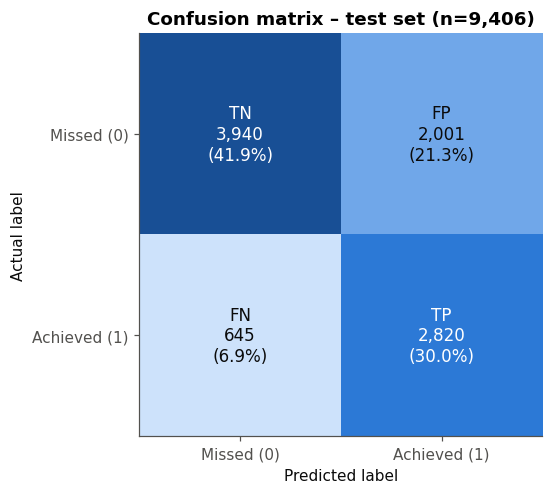

In [29]:
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95"])
fig, ax = plt.subplots(figsize=(6.0, 4.6))
mat = np.array([[TN, FP], [FN, TP]])
ax.imshow(mat, cmap=blues)
ax.grid(False)
names = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{names[i][j]}\n{mat[i, j]:,}\n({mat[i, j] / N:.1%})", ha="center", va="center",
                color="white" if mat[i, j] > mat.max() * 0.55 else INK, fontsize=11)
ax.set_xticks([0, 1], ["Missed (0)", "Achieved (1)"]); ax.set_yticks([0, 1], ["Missed (0)", "Achieved (1)"])
ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label")
ax.set_title(f"Confusion matrix – test set (n={N:,})")
fig.tight_layout(); fig.savefig(EVIDENCE / "confusion_matrix.png"); plt.show()

**Interpretation:** the diagonal (TN, TP) holds the correct predictions. FP are days the model expected
the user to hit the goal but they missed it. FN are days the user hit the goal but the model predicted a miss.

### 6.7 Accuracy

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

In [30]:
accuracy_manual = (TP + TN) / N
accuracy_spark = mc(pred, "accuracy")
print(f"Accuracy = ({TP} + {TN}) / ({TP} + {TN} + {FP} + {FN}) = {TP + TN} / {N} = {accuracy_manual:.4f}")
print(f"Spark MulticlassClassificationEvaluator(metricName='accuracy') = {accuracy_spark:.4f}")
assert np.isclose(accuracy_manual, accuracy_spark)

Accuracy = (2820 + 3940) / (2820 + 3940 + 2001 + 645) = 6760 / 9406 = 0.7187
Spark MulticlassClassificationEvaluator(metricName='accuracy') = 0.7187


### 6.8 Precision

Precision for the positive class (goal achieved): of all days predicted "achieved", how many really were.

$$\text{Precision} = \frac{TP}{TP + FP}$$

In [31]:
precision_manual = TP / (TP + FP)
precision_spark = mc(pred, "precisionByLabel", 1.0)
print(f"Precision = {TP} / ({TP} + {FP}) = {precision_manual:.4f}")
print(f"Spark evaluator (precisionByLabel, metricLabel=1) = {precision_spark:.4f}")
assert np.isclose(precision_manual, precision_spark)

Precision = 2820 / (2820 + 2001) = 0.5849
Spark evaluator (precisionByLabel, metricLabel=1) = 0.5849


### 6.9 Recall

Recall for the positive class: of all days where the goal was really achieved, how many the model caught.

$$\text{Recall} = \frac{TP}{TP + FN}$$

In [32]:
recall_manual = TP / (TP + FN)
recall_spark = mc(pred, "recallByLabel", 1.0)
print(f"Recall = {TP} / ({TP} + {FN}) = {recall_manual:.4f}")
print(f"Spark evaluator (recallByLabel, metricLabel=1) = {recall_spark:.4f}")
assert np.isclose(recall_manual, recall_spark)

Recall = 2820 / (2820 + 645) = 0.8139
Spark evaluator (recallByLabel, metricLabel=1) = 0.8139


### 6.10 F1 Score

$$F_1 = \frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

In [33]:
f1_manual = 2 * precision_manual * recall_manual / (precision_manual + recall_manual)
f1_spark = mc(pred, "fMeasureByLabel", 1.0)
print(f"F1 = 2 x {precision_manual:.4f} x {recall_manual:.4f} / ({precision_manual:.4f} + {recall_manual:.4f}) = {f1_manual:.4f}")
print(f"Spark evaluator (fMeasureByLabel, metricLabel=1) = {f1_spark:.4f}")
assert np.isclose(f1_manual, f1_spark)

F1 = 2 x 0.5849 x 0.8139 / (0.5849 + 0.8139) = 0.6807
Spark evaluator (fMeasureByLabel, metricLabel=1) = 0.6807


**Interpretation (6.7–6.10):** each metric was computed twice, once by hand from the confusion-matrix
counts and once by Spark MLlib's evaluator, and the `assert` statements prove the two agree. This is the
answer to *"How exactly did you calculate the accuracy?"*

### 6.11 Classification Results

In [34]:
roc_auc = auc_eval.evaluate(pred)
majority_share = max(TP + FN, TN + FP) / N
classification_results = pd.DataFrame([
    ("Accuracy", accuracy_spark, "(TP+TN)/N"),
    ("Precision (class 1 = achieved)", precision_spark, "TP/(TP+FP)"),
    ("Recall (class 1 = achieved)", recall_spark, "TP/(TP+FN)"),
    ("F1 Score (class 1 = achieved)", f1_spark, "2PR/(P+R)"),
    ("ROC-AUC", roc_auc, "BinaryClassificationEvaluator"),
    ("Weighted precision (both classes)", mc(pred, "weightedPrecision"), "class-size weighted"),
    ("Weighted recall (both classes)", mc(pred, "weightedRecall"), "class-size weighted"),
    ("Weighted F1 (both classes)", mc(pred, "f1"), "class-size weighted"),
    ("Baseline: always predict majority class", majority_share, "reference only"),
], columns=["Metric", "Value", "Formula / source"])
classification_results["Actual Score"] = classification_results["Value"].map(lambda v: f"{v:.2%}")
classification_results.to_csv(EVIDENCE / "classification_results.csv", index=False)
display(classification_results[["Metric", "Actual Score", "Formula / source"]])

,Metric,Actual Score,Formula / source
0,Accuracy,71.87%,(TP+TN)/N
1,Precision (class 1 = achieved),58.49%,TP/(TP+FP)
2,Recall (class 1 = achieved),81.39%,TP/(TP+FN)
3,F1 Score (class 1 = achieved),68.07%,2PR/(P+R)
4,ROC-AUC,82.47%,BinaryClassificationEvaluator
5,Weighted precision (both classes),75.82%,class-size weighted
6,Weighted recall (both classes),71.87%,class-size weighted
7,Weighted F1 (both classes),72.36%,class-size weighted
8,Baseline: always predict majority class,63.16%,reference only


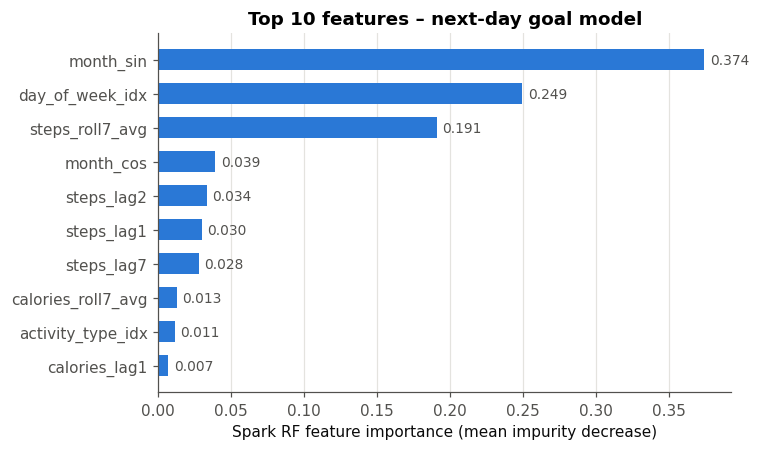

In [35]:
fi = pd.DataFrame({"Feature": assembler.getInputCols(), "Importance": rf_model.featureImportances.toArray()})
fi = fi.sort_values("Importance", ascending=False).reset_index(drop=True)
fi.to_csv(EVIDENCE / "rf_feature_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.2))
top = fi.head(10).iloc[::-1]
ax.barh(top.Feature, top.Importance, color=BLUE, height=0.6)
for y, v in enumerate(top.Importance):
    ax.text(v + fi.Importance.max() * 0.01, y, f"{v:.3f}", va="center", color=MUTED, fontsize=9)
ax.set_xlabel("Spark RF feature importance (mean impurity decrease)")
ax.set_title("Top 10 features – next-day goal model"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(EVIDENCE / "rf_feature_importance.png"); plt.show()

**Interpretation:** accuracy must be compared with the majority-class baseline ("always predict
missed", the last row). The model is above that baseline, and its ROC-AUC shows it ranks achieved days
above missed days far better than chance (50%). Because of the class weighting, the model favours
**recall** over precision: it catches most days on which the goal will be achieved, at the cost of some false
alarms (FP). For a motivational fitness app that is a reasonable trade-off.
The feature importances show the prediction is driven mostly by **seasonality** (`month_sin`),
**day of week** and the user's **recent 7-day step trend**. The dataset has a real seasonal and weekly
rhythm, and a goal based on the yearly average is easier to hit in high-activity months.

### 6.12 Robustness Check – Chronological (Out-of-Time) Split

The existing project script trains on dates **before 2024-10-15** and tests on dates **on or after** it.
Here we rerun that same methodology with the Spark Random Forest (same features and the selected depth),
to show how much performance depends on the split strategy.

In [36]:
CUTOFF = "2024-10-15"   # models/train_goal_achievement.py TRAIN_CUTOFF
chrono_train, chrono_test = model_df.filter(F.col("date") < CUTOFF), model_df.filter(F.col("date") >= CUTOFF)
chrono_train_w, chrono_pos = add_balanced_weights(chrono_train)
chrono_model = Pipeline(stages=indexers + [assembler, make_rf(BEST_DEPTH)]).fit(chrono_train_w)
cp = chrono_model.transform(chrono_test).cache()
chrono = pd.DataFrame([{
    "Split": "Random 70/15/15 (this notebook, test set)", "Train rows": train.count(), "Test rows": N,
    "Test positive rate": f"{(TP + FN) / N:.2%}", "Accuracy": accuracy_spark, "Precision": precision_spark,
    "Recall": recall_spark, "F1": f1_spark, "ROC-AUC": roc_auc}, {
    "Split": f"Chronological (train < {CUTOFF})", "Train rows": chrono_train.count(), "Test rows": cp.count(),
    "Test positive rate": f"{cp.filter(F.col(CLS_TARGET) == 1).count() / cp.count():.2%}",
    "Accuracy": mc(cp, "accuracy"), "Precision": mc(cp, "precisionByLabel", 1.0),
    "Recall": mc(cp, "recallByLabel", 1.0), "F1": mc(cp, "fMeasureByLabel", 1.0), "ROC-AUC": auc_eval.evaluate(cp)}])
chrono.to_csv(EVIDENCE / "classification_split_comparison.csv", index=False)
display(chrono.round(4))

,Split,Train rows,Test rows,Test positive rate,Accuracy,Precision,Recall,F1,ROC-AUC
0,"Random 70/15/15 (this notebook, test set)",43996,9406,36.84%,0.7187,0.5849,0.8139,0.6807,0.8247
1,Chronological (train < 2024-10-15),53026,9760,11.80%,0.8608,0.3876,0.3099,0.3444,0.7262


**Interpretation:** the chronological test period (mid-October to December) falls in the dataset's
seasonal low-activity period. Far fewer test days reach the yearly-average-based goal (see "Test positive
rate"), and the model must extrapolate to months it never saw.
* **Accuracy looks *higher* under the chronological split, but that is misleading.** Most test days are
  "missed", so predicting "missed" is already right most of the time. The class-1 **precision, recall, F1
  and ROC-AUC are all lower**, and those are the honest measures here.
* For cross-checking: `models/metrics_report.md` documents the existing *scikit-learn* Random Forest on
  this same chronological split as F1 0.344 / ROC-AUC 0.718. The Spark MLlib model above lands in the same range.

**Both results are real and both should be reported.** The random split measures "predict a known user's
next day". The chronological split is the stricter forecast-the-future test that the original project
script used.

## 7. Clustering Problem – K-Means

### 7.1 Problem Statement

**Question:** *What distinct types of activity day exist in the data, and how does each user's mix of
day types differ?* K-Means is unsupervised: no label is used, and quality is judged with the internal
silhouette score. K-Means did **not** exist in the repository before this notebook.

### 7.2 Clustering Features

**Day-level or user-level?** We first check whether *users* actually differ in their average behaviour.

In [37]:
CANDIDATES = ["steps", "active_minutes", "sedentary_minutes", "calories_burned", "avg_heart_rate",
              "resting_heart_rate", "sleep_minutes"]
per_user = silver.groupBy("user_id").agg(*[F.avg(c).alias(c) for c in CANDIDATES])
spread = pd.DataFrame({
    "Feature": CANDIDATES,
    "Std across daily records": [silver.agg(F.stddev(c)).first()[0] for c in CANDIDATES],
    "Std across per-user averages": [per_user.agg(F.stddev(c)).first()[0] for c in CANDIDATES],
    "Avg within-user std": [silver.groupBy("user_id").agg(F.stddev(c).alias("s")).agg(F.avg("s")).first()[0]
                            for c in CANDIDATES],
}).round(2)
display(spread)
viol = silver.filter(F.col("sedentary_minutes") != 1440 - F.col("sleep_minutes") - F.col("active_minutes")).count()
print("Rows where sedentary_minutes != 1440 - sleep_minutes - active_minutes:", viol)

,Feature,Std across daily records,Std across per-user averages,Avg within-user std
0,steps,2057.20,115.28,2056.64
1,active_minutes,29.09,1.78,29.09
2,sedentary_minutes,65.37,4.09,65.32
3,calories_burned,437.75,112.20,418.25
4,avg_heart_rate,17.77,10.12,14.63
5,resting_heart_rate,5.27,5.27,0.00
6,sleep_minutes,58.38,3.68,58.32


Rows where sedentary_minutes != 1440 - sleep_minutes - active_minutes: 0


**Interpretation and feature choice (based on the output above):**
* Per-user **average** steps, active minutes, sedentary minutes and sleep are almost identical across
  users (tiny std across per-user averages). Clustering *users* on averages would separate them mainly on
  body-weight-driven calories, not on behaviour. The real behavioural variation is **day to day**, so we
  cluster the **daily records**, then profile each user by their mix of day types (§7.9).
* `resting_heart_rate` has zero within-user variation. It is a constant per-user trait, not daily behaviour,
  so it is **excluded** as an input.
* `sedentary_minutes` is an exact linear function of sleep and active minutes (0 violations), so it adds no
  new information and would double-weight those two. It is **excluded** as an input but **kept** for describing clusters.
* **Final inputs:** steps, active_minutes, calories_burned, avg_heart_rate, sleep_minutes.

### 7.3 Feature Scaling

The features have very different units (≈8,600 steps vs ≈70 minutes). Without scaling, K-Means
distances would be dominated by `steps`. `StandardScaler(withMean=True, withStd=True)` puts every
feature on mean 0, standard deviation 1.

In [38]:
km_assembler = VectorAssembler(inputCols=KM_FEATURES, outputCol="km_raw")
km_scaler = StandardScaler(inputCol="km_raw", outputCol="km_features", withMean=True, withStd=True)
km_raw = km_assembler.transform(silver)
scaler_model = km_scaler.fit(km_raw)
km_data = scaler_model.transform(km_raw).cache()

scaling = pd.DataFrame({"Feature": KM_FEATURES, "Mean (original units)": scaler_model.mean.toArray(),
                        "Std (original units)": scaler_model.std.toArray()}).round(2)
display(scaling)
check = km_data.select(vector_to_array("km_features").alias("z")).select(
    *[F.col("z")[i].alias(f) for i, f in enumerate(KM_FEATURES)])
print("After scaling (should be mean ~0, std ~1):")
check.describe().show()

,Feature,Mean (original units),Std (original units)
0,steps,8624.77,2057.20
1,active_minutes,69.93,29.09
2,calories_burned,662.20,437.75
3,avg_heart_rate,130.82,17.77
4,sleep_minutes,422.83,58.38


After scaling (should be mean ~0, std ~1):


+-------+--------------------+--------------------+--------------------+--------------------+--------------------+
|summary|               steps|      active_minutes|     calories_burned|      avg_heart_rate|       sleep_minutes|
+-------+--------------------+--------------------+--------------------+--------------------+--------------------+
|  count|              100122|              100122|              100122|              100122|              100122|
|   mean|-2.40722414623984...|-5.43974463541953...|-1.57377955975869...|-5.01883524829251...|2.516017619594378...|
| stddev|  1.0000000000000007|                 1.0|  1.0000000000000009|  0.9999999999999993|  1.0000000000000009|
|    min| -3.9115088647574647| -1.7160979523361437| -1.4030782253312617|  -2.691364596213823| -3.1316198815268415|
|    max|  3.7829189175575224|   1.720948581320829|   7.000524805170416|    4.23186039146961|  3.0346906840302004|
+-------+--------------------+--------------------+--------------------+--------

### 7.4 K Selection

Train K-Means for **K = 2…6** (seed 42) on all daily records. For each K we compute the **silhouette
score** (Spark `ClusteringEvaluator`, squared Euclidean distance) and the within-cluster sum of squares
(WSSSE, the elbow curve). Silhouette ranges from −1 to 1. Higher means points sit closer to their own
cluster than to the nearest other cluster.

In [39]:
sil_eval = ClusteringEvaluator(featuresCol="km_features", predictionCol="cluster",
                               metricName="silhouette", distanceMeasure="squaredEuclidean")
from pyspark.ml.clustering import KMeans
k_rows, km_models = [], {}
for k in range(2, 7):
    km = KMeans(k=k, seed=SEED, featuresCol="km_features", predictionCol="cluster", maxIter=50).fit(km_data)
    km_models[k] = km
    k_rows.append({"K": k, "Silhouette Score": sil_eval.evaluate(km.transform(km_data)),
                   "WSSSE": km.summary.trainingCost, "Cluster sizes": km.summary.clusterSizes})
k_eval = pd.DataFrame(k_rows)

### 7.5 Silhouette Score

,K,Silhouette Score,WSSSE,Cluster sizes
0,2,0.3528,385945.7,"[45306, 54816]"
1,3,0.2879,339763.5,"[42853, 32288, 24981]"
2,4,0.2676,305986.0,"[26285, 25521, 21665, 26651]"
3,5,0.2664,280162.1,"[21604, 19262, 19078, 22787, 17391]"
4,6,0.2777,255665.0,"[17354, 16024, 13554, 17805, 17824, 17561]"


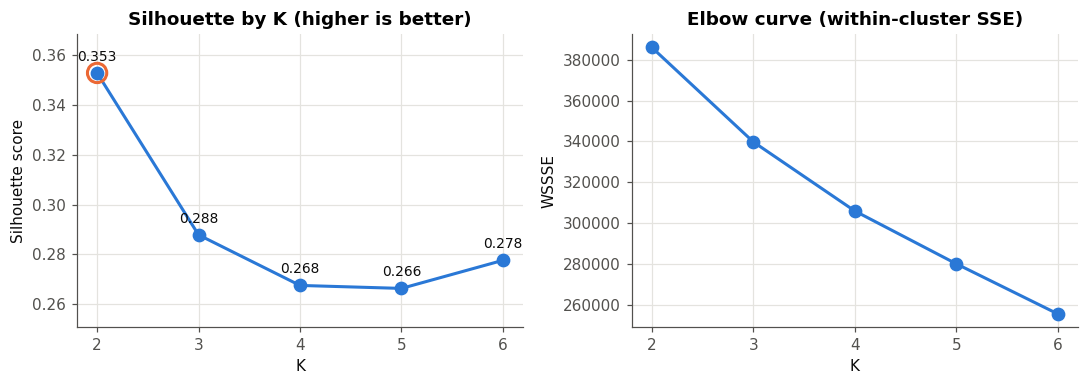

Selected K = 2 (highest silhouette score: 0.3528)


In [40]:
silhouette_scores = k_eval[["K", "Silhouette Score", "WSSSE"]].copy()
silhouette_scores["Silhouette Score"] = silhouette_scores["Silhouette Score"].round(4)
silhouette_scores["WSSSE"] = silhouette_scores["WSSSE"].round(1)
silhouette_scores.to_csv(EVIDENCE / "silhouette_scores.csv", index=False)
display(k_eval.assign(**{"Silhouette Score": k_eval["Silhouette Score"].round(4),
                         "WSSSE": k_eval["WSSSE"].round(1)}))

BEST_K = int(k_eval.loc[k_eval["Silhouette Score"].idxmax(), "K"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.plot(k_eval.K, k_eval["Silhouette Score"], color=BLUE, lw=2, marker="o", ms=8)
for k, s in zip(k_eval.K, k_eval["Silhouette Score"]):
    ax.annotate(f"{s:.3f}", (k, s), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=INK)
ax.scatter([BEST_K], [k_eval["Silhouette Score"].max()], s=160, facecolors="none", edgecolors=ORANGE, lw=2, zorder=3)
ax.margins(y=0.18); ax.set_xticks(k_eval.K); ax.set_xlabel("K"); ax.set_ylabel("Silhouette score"); ax.set_title("Silhouette by K (higher is better)")
ax = axes[1]
ax.plot(k_eval.K, k_eval["WSSSE"], color=BLUE, lw=2, marker="o", ms=8)
ax.set_xticks(k_eval.K); ax.set_xlabel("K"); ax.set_ylabel("WSSSE"); ax.set_title("Elbow curve (within-cluster SSE)")
fig.tight_layout(); fig.savefig(EVIDENCE / "silhouette_scores.png"); plt.show()
print(f"Selected K = {BEST_K} (highest silhouette score: {k_eval['Silhouette Score'].max():.4f})")

**Interpretation:** K is chosen by the **highest actual silhouette score** (circled in orange), not
assumed in advance. The elbow curve always decreases as K grows, so it is shown only as supporting
context. The silhouette values are moderate rather than high, meaning the day types overlap: daily
behaviour forms a continuum rather than perfectly separate groups. We state that openly.

### 7.6 Final K-Means Model

In [41]:
final_km = km_models[BEST_K]
clustered = final_km.transform(km_data).cache()
centers_scaled = np.array(final_km.clusterCenters())
centers_original = centers_scaled * scaler_model.std.toArray() + scaler_model.mean.toArray()
centers = pd.DataFrame(centers_original, columns=KM_FEATURES).round(1)
centers.index.name = "cluster"
print(f"Final model: K = {BEST_K}, seed = {SEED}, distance = squared Euclidean, iterations = {final_km.summary.numIter}")
print("Cluster centers converted back to original units:")
display(centers)
print("Sample cluster assignments:")
clustered.select("user_id", "date", *KM_FEATURES, "cluster").show(10)

Final model: K = 2, seed = 42, distance = squared Euclidean, iterations = 19
Cluster centers converted back to original units:


,steps,active_minutes,calories_burned,avg_heart_rate,sleep_minutes
cluster,,,,,
0,8456.6,95.5,994.4,133.8,423.2
1,8763.8,48.8,387.7,128.4,422.5


Sample cluster assignments:


+-------+----------+-----+--------------+---------------+--------------+-------------+-------+
|user_id|      date|steps|active_minutes|calories_burned|avg_heart_rate|sleep_minutes|cluster|
+-------+----------+-----+--------------+---------------+--------------+-------------+-------+
|     52|2024-03-01| 8410|            92|          746.1|           118|          438|      0|
|     52|2024-03-02|11429|            61|          314.5|           135|          408|      1|
|     52|2024-03-03|11262|            73|          377.7|           130|          534|      1|
|     52|2024-03-04|11391|           101|          523.9|           122|          342|      0|
|     52|2024-03-05| 9630|            73|          300.0|           107|          294|      1|
|     52|2024-03-06| 7955|            40|          208.7|           116|          390|      1|
|     52|2024-03-08|11120|            92|          380.4|           109|          462|      1|
|     52|2024-03-09|11638|            42|         

### 7.7 Cluster Distribution

,cluster,Daily records,Distinct users,Share of records
0,0,45306,437,45.25%
1,1,54816,437,54.75%


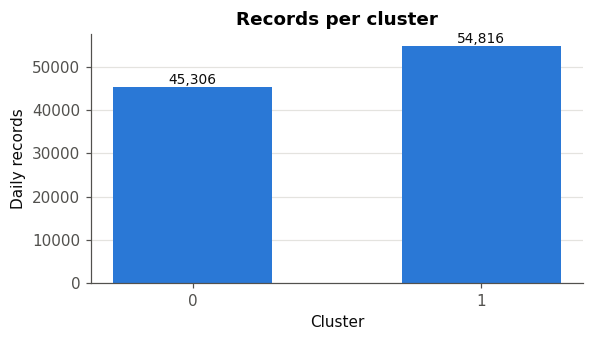

In [42]:
total_days = clustered.count()
dist = (clustered.groupBy("cluster")
        .agg(F.count("*").alias("Daily records"), F.countDistinct("user_id").alias("Distinct users"))
        .orderBy("cluster").toPandas())
dist["Share of records"] = (dist["Daily records"] / total_days).map(lambda v: f"{v:.2%}")
assert dist["Daily records"].sum() == total_days
display(dist)

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.bar(dist.cluster.astype(str), dist["Daily records"], color=BLUE, width=0.55)
for x, v in enumerate(dist["Daily records"]):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xlabel("Cluster"); ax.set_ylabel("Daily records"); ax.set_title("Records per cluster"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(EVIDENCE / "cluster_sizes.png"); plt.show()

### 7.8 Cluster Characteristics

Average values per cluster for **all** relevant columns, including the ones not used as inputs, plus how far
each is from the overall mean.

In [43]:
PROFILE = ["steps", "active_minutes", "sedentary_minutes", "calories_burned", "avg_heart_rate",
           "max_heart_rate", "resting_heart_rate", "sleep_minutes", "sleep_quality_score", "distance_km"]
profile = (clustered.groupBy("cluster").agg(F.count("*").alias("records"), *[F.avg(c).alias(c) for c in PROFILE])
           .orderBy("cluster").toPandas().set_index("cluster"))
overall = clustered.agg(*[F.avg(c).alias(c) for c in PROFILE]).toPandas().iloc[0]
rel = ((profile[PROFILE] / overall - 1) * 100).round(1)
display(profile.round(1))
print("Difference from overall mean (%):")
display(rel)

intensity_mix = (clustered.groupBy("cluster").pivot("intensity", ["Low", "Medium", "High"]).count()
                 .orderBy("cluster").toPandas().set_index("cluster"))
intensity_mix = (intensity_mix.div(intensity_mix.sum(axis=1), axis=0) * 100).round(1)
print("Intensity mix per cluster (% of the cluster's days):")
display(intensity_mix)
act = clustered.groupBy("cluster", "activity_type").count().toPandas()
act_mix = act.pivot(index="cluster", columns="activity_type", values="count").fillna(0)
act_mix = (act_mix.div(act_mix.sum(axis=1), axis=0) * 100).round(1)
print("Activity-type mix per cluster (%):")
display(act_mix)

,records,steps,active_minutes,sedentary_minutes,calories_burned,avg_heart_rate,max_heart_rate,resting_heart_rate,sleep_minutes,sleep_quality_score,distance_km
cluster,,,,,,,,,,,
0,45306,8456.5,95.5,921.2,994.4,133.8,148.7,70.0,423.2,67.2,6.5
1,54816,8763.9,48.8,968.8,387.7,128.4,141.8,69.9,422.5,67.1,6.6


Difference from overall mean (%):


,steps,active_minutes,sedentary_minutes,calories_burned,avg_heart_rate,max_heart_rate,resting_heart_rate,sleep_minutes,sleep_quality_score,distance_km
cluster,,,,,,,,,,
0,-2.0,36.6,-2.7,50.2,2.3,2.6,0.1,0.1,0.1,-0.4
1,1.6,-30.3,2.3,-41.5,-1.9,-2.2,-0.1,-0.1,-0.1,0.3


Intensity mix per cluster (% of the cluster's days):


,Low,Medium,High
cluster,,,
0,23.0,51.7,25.3
1,36.1,48.4,15.5


Activity-type mix per cluster (%):


activity_type,Basketball,Cycling,Dancing,HIIT,Running,Swimming,Tennis,Walking,Weight Training,Yoga
cluster,,,,,,,,,,
0,10.4,11.4,9.3,12.1,12.1,10.9,10.4,7.6,8.7,7.1
1,9.5,10.2,11.2,8.7,7.4,8.9,9.0,11.2,11.1,12.8


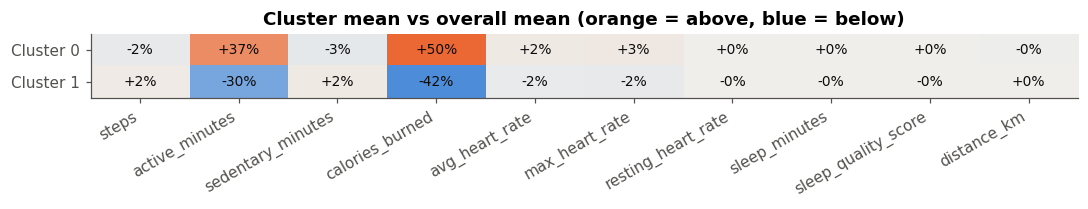

In [44]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])
lim = float(np.abs(rel.values).max())
fig, ax = plt.subplots(figsize=(10, 0.9 + 0.55 * len(rel)))
ax.imshow(rel.values, cmap=div, norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim), aspect="auto")
ax.grid(False)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        ax.text(j, i, f"{rel.values[i, j]:+.0f}%", ha="center", va="center", fontsize=9, color=INK)
ax.set_xticks(range(len(PROFILE)), PROFILE, rotation=30, ha="right")
ax.set_yticks(range(len(rel)), [f"Cluster {c}" for c in rel.index])
ax.set_title("Cluster mean vs overall mean (orange = above, blue = below)")
fig.tight_layout(); fig.savefig(EVIDENCE / "cluster_profile_heatmap.png"); plt.show()

### 7.9 Cluster Interpretation

Labels are assigned by a **transparent rule applied to the computed averages**, not by cluster number:
clusters are ranked by mean `active_minutes` (session length). Each label is then explained by listing
the features that differ by more than 5% from the overall mean.

In [45]:
order = profile["active_minutes"].sort_values().index.tolist()          # lowest -> highest session length
tier_names = {2: ["Light / short-session days", "High-effort / long-session days"],
              3: ["Light days", "Moderate days", "High-effort days"]}
names = tier_names.get(BEST_K, [f"Effort tier {i+1} of {BEST_K}" for i in range(BEST_K)])
cluster_label = {c: names[r] for r, c in enumerate(order)}

summary_rows = []
for c in profile.index:
    notable = [f"{f} {rel.loc[c, f]:+.1f}% ({profile.loc[c, f]:,.1f})" for f in PROFILE if abs(rel.loc[c, f]) > 5]
    summary_rows.append({"Cluster": c, "Count": int(profile.loc[c, "records"]),
                         "Share": f"{profile.loc[c, 'records'] / total_days:.2%}",
                         "Main characteristics (vs overall mean)": "; ".join(notable) or "close to overall mean",
                         "Interpretation": cluster_label[c]})
cluster_summary = pd.DataFrame(summary_rows)
cluster_summary.to_csv(EVIDENCE / "cluster_summary.csv", index=False)
pd.set_option("display.max_colwidth", 200)
display(cluster_summary)

,Cluster,Count,Share,Main characteristics (vs overall mean),Interpretation
0,0,45306,45.25%,active_minutes +36.6% (95.5); calories_burned +50.2% (994.4),High-effort / long-session days
1,1,54816,54.75%,active_minutes -30.3% (48.8); calories_burned -41.5% (387.7),Light / short-session days


**Personalization: each user's mix of day types.** Because clusters describe *days*, every user gets a
personal profile, the share of their own days that fall in each cluster. This is what turns clustering
into a per-user insight (for example, "only X% of your days are high-effort days, versus a typical user's Y%").

In [46]:
user_mix = (clustered.groupBy("user_id").pivot("cluster", sorted(cluster_label)).count().fillna(0).toPandas()
            .set_index("user_id"))
user_mix = user_mix.div(user_mix.sum(axis=1), axis=0) * 100
user_mix.columns = [f"% days in cluster {c} ({cluster_label[int(c)]})" for c in user_mix.columns]
user_mix.round(2).to_csv(EVIDENCE / "user_cluster_mix.csv")
print("Distribution across all users of the share of their days in each cluster:")
display(user_mix.describe().round(1))
print("Dashboard demo users (demo1=1503, demo2=2759, demo3=2373):")
display(user_mix.loc[[1503, 2759, 2373]].round(1))

Distribution across all users of the share of their days in each cluster:


,% days in cluster 0 (High-effort / long-session days),% days in cluster 1 (Light / short-session days)
count,437.0,437.0
mean,45.2,54.8
std,5.5,5.5
min,31.7,38.4
25%,41.4,51.4
50%,45.0,55.0
75%,48.6,58.6
max,61.6,68.3


Dashboard demo users (demo1=1503, demo2=2759, demo3=2373):


,% days in cluster 0 (High-effort / long-session days),% days in cluster 1 (Light / short-session days)
user_id,,
1503,55.7,44.3
2759,35.7,64.3
2373,45.9,54.1


**Interpretation (read with the tables in 7.8 and 7.9):**
* The clusters separate mainly on **session length and energy expenditure**. `active_minutes` and
  `calories_burned` are the only features more than 5% from the overall mean. The high-effort cluster also has
  a larger share of *High*-intensity sessions and of HIIT/Running, and the light cluster has more
  Yoga/Walking/Weight-training days (activity-type table).
* **Steps, sleep, heart rate and sleep quality barely differ** between clusters. In this dataset a
  high-effort day means a longer and harder workout, not more walking, so labelling the clusters by step count
  ("highly active walkers") would be wrong.
* Sedentary minutes are only slightly lower on high-effort days, as expected from the 1440-minute identity.
* Every user has days in both clusters, and the share of high-effort days varies by user (table above).
  That share is the personalized signal: for example, a recommendation can target users whose
  high-effort share is below the population median.

## 8. Big Data / Spark Evidence

### 8.1 Spark Session

In [47]:
sc = spark.sparkContext
jvm = spark._jvm
hadoop_conf = sc._jsc.hadoopConfiguration()
spark_info = {
    "Spark version": spark.version,
    "Application name": sc.appName,
    "Application id": sc.applicationId,
    "Master": sc.master,
    "Default parallelism (cores used)": sc.defaultParallelism,
    "spark.sql.shuffle.partitions": spark.conf.get("spark.sql.shuffle.partitions"),
    "Spark UI": sc.uiWebUrl,
    "JVM Java version": jvm.System.getProperty("java.version"),
    "Hadoop client library version": jvm.org.apache.hadoop.util.VersionInfo.getVersion(),
    "fs.defaultFS (default filesystem)": hadoop_conf.get("fs.defaultFS"),
}
display(pd.DataFrame(spark_info.items(), columns=["Property", "Value"]))

,Property,Value
0,Spark version,4.0.1
1,Application name,FitPulse-Faculty-Demo
2,Application id,local-1791224961473
3,Master,local[*]
4,Default parallelism (cores used),12
5,spark.sql.shuffle.partitions,8
6,Spark UI,http://127.0.0.1:4040
7,JVM Java version,17.0.20.1
8,Hadoop client library version,3.4.1
9,fs.defaultFS (default filesystem),file:///


### 8.2 Distributed Data Processing

The physical plans show how Spark parallelises the ETL's operations. The window functions use an
`Exchange hashpartitioning(user_id)` (shuffle) followed by `Window`. The per-user goal aggregation runs as
a partial `HashAggregate` on each partition (map side), an `Exchange` (shuffle), then a final
`HashAggregate` (reduce side), which is the MapReduce pattern. The join with the per-user table is a
`BroadcastHashJoin`.

In [48]:
def plan_of(df):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain()
    return buf.getvalue()

etl_like = (bronze.withColumn("steps_lag1", F.lag("steps", 1).over(Window.partitionBy("user_id").orderBy("date"))))
goals = bronze.groupBy("user_id").agg(F.avg("steps").alias("user_avg_steps"))
joined = bronze.join(F.broadcast(goals), "user_id")
plans = {"Window / lag feature (spark_etl.py L79-82)": plan_of(etl_like),
         "groupBy(user_id).agg - personalized goal (spark_etl.py L99-104)": plan_of(goals),
         "Broadcast join (spark_etl.py L115)": plan_of(joined)}
for title, p in plans.items():
    print("=" * 100, "\n", title, "\n", "=" * 100, "\n", p, sep="")

Window / lag feature (spark_etl.py L79-82)
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Window [lag(steps#58, -1, null) windowspecdefinition(user_id#56, date#57 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) AS steps_lag1#133368], [user_id#56], [date#57 ASC NULLS FIRST]
   +- Sort [user_id#56 ASC NULLS FIRST, date#57 ASC NULLS FIRST], false, 0
      +- Exchange hashpartitioning(user_id#56, 8), ENSURE_REQUIREMENTS, [plan_id=11508]
         +- FileScan csv [user_id#56,date#57,steps#58,calories_burned#59,distance_km#60,active_minutes#61,sedentary_minutes#62,resting_heart_rate#63,avg_heart_rate#64,max_heart_rate#65,sleep_minutes#66,sleep_quality_score#67,activity_type#68,intensity#69,age#70,gender#71,height_cm#72,weight_kg#73,bmi#74,health_condition#75,smoking_status#76,stress_level#77,hydration_level#78] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/D:/bigdata/fitpulsee/FitPulse/data/raw/fitpulse_raw.csv], PartitionFilters

In [49]:
mllib_stages = pd.DataFrame(
    [("Classification", type(s).__name__) for s in rf_pipeline_model.stages]
    + [("Clustering", type(s).__name__) for s in (km_assembler, scaler_model, final_km)],
    columns=["Workflow", "Spark MLlib stage"])
print("Spark MLlib components used in this notebook:")
display(mllib_stages)

Spark MLlib components used in this notebook:


,Workflow,Spark MLlib stage
0,Classification,StringIndexerModel
1,Classification,StringIndexerModel
2,Classification,StringIndexerModel
3,Classification,VectorAssembler
4,Classification,RandomForestClassificationModel
5,Clustering,VectorAssembler
6,Clustering,StandardScalerModel
7,Clustering,KMeansModel


### 8.3 Partitions

In [50]:
silver_files = sorted(Path(SILVER_PATH).rglob("*.parquet"))
by_month = pd.Series([f.parent.name for f in silver_files]).value_counts().sort_index()
storage = pd.DataFrame({"Parquet files": by_month,
                        "Size (KB)": [round(sum(f.stat().st_size for f in silver_files if f.parent.name == m) / 1024, 1)
                                      for m in by_month.index]})
print(f"Silver layer on disk: {len(silver_files)} Parquet files in {len(by_month)} month partitions, "
      f"{sum(f.stat().st_size for f in silver_files) / 1024 / 1024:.2f} MB total")
display(storage)

print("Bronze DataFrame in-memory partitions :", bronze.rdd.getNumPartitions())
print("Silver DataFrame in-memory partitions :", silver.rdd.getNumPartitions())
print("Records per in-memory Silver partition:")
(silver.groupBy(F.spark_partition_id().alias("partition_id")).count().orderBy("partition_id").show(50))

Silver layer on disk: 96 Parquet files in 12 month partitions, 6.97 MB total


,Parquet files,Size (KB)
month=2024-01,8,626.5
month=2024-02,8,635.7
month=2024-03,8,691.3
month=2024-04,8,677.3
month=2024-05,8,670.1
month=2024-06,8,617.8
month=2024-07,8,588.1
month=2024-08,8,549.0
month=2024-09,8,515.5
month=2024-10,8,530.2


Bronze DataFrame in-memory partitions : 3
Silver DataFrame in-memory partitions : 12
Records per in-memory Silver partition:


+------------+-----+
|partition_id|count|
+------------+-----+
|           0|10708|
|           1|10170|
|           2| 9671|
|           3| 9431|
|           4| 8838|
|           5| 8539|
|           6| 7948|
|           7| 7618|
|           8| 7272|
|           9| 7064|
|          10| 7526|
|          11| 5337|
+------------+-----+



In [51]:
march = silver.filter(F.col("month") == "2024-03")
march_plan = plan_of(march)
print("Partition pruning - query for month = 2024-03 only reads that folder:")
scan = [line for line in march_plan.splitlines() if "FileScan parquet" in line][0]
print("PartitionFilters:", re.search(r"PartitionFilters: \[(.*?)\]", scan).group(1))
print("Location        :", re.search(r"Location: InMemoryFileIndex\(\d+ paths\)\[(.*?)\]", scan).group(1))
print("\nRows in 2024-03 partition:", march.count())

Partition pruning - query for month = 2024-03 only reads that folder:
PartitionFilters: isnotnull(month#117), (month#117 = 2024-03)
Location        : file:/D:/bigdata/fitpulsee/FitPulse/data/processed/fitpulse_silver



Rows in 2024-03 partition: 10246


### 8.4 HDFS Evidence (baseline recorded BEFORE the HDFS upgrade)

The check below looks for a Hadoop/HDFS installation and the configured default filesystem, and does not
assume either. **Its saved output is the local-only baseline** from the session in which sections 1-10 were
executed (no HDFS on that PATH). The HDFS integration and its verification are in **section 11**.

In [52]:
hdfs_bin = shutil.which("hdfs")
print("`hdfs` command on PATH :", hdfs_bin)
print("fs.defaultFS           :", hadoop_conf.get("fs.defaultFS"))
if hdfs_bin:
    out = subprocess.run([hdfs_bin, "dfs", "-ls", "/"], capture_output=True, text=True)
    print(out.stdout or out.stderr)
else:
    print("\nRESULT: HDFS is NOT installed/configured on this machine. The Silver layer is stored as\n"
          "partitioned Parquet on the local filesystem through Hadoop's FileSystem API (file:///),\n"
          "i.e. the same storage format/partition layout HDFS would hold, but not HDFS itself.")

evidence_txt = ["SPARK SESSION"] + [f"{k}: {v}" for k, v in spark_info.items()]
evidence_txt += ["", f"hdfs command on PATH: {hdfs_bin}", "",
                 f"Silver: {len(silver_files)} parquet files, {len(by_month)} month partitions",
                 storage.to_string(), "", "Bronze partitions: " + str(bronze.rdd.getNumPartitions()),
                 "Silver partitions: " + str(silver.rdd.getNumPartitions()), ""]
evidence_txt += [f"--- {t} ---\n{p}" for t, p in plans.items()] + ["--- Partition pruning ---", march_plan]
(EVIDENCE / "spark_hdfs_evidence.txt").write_text("\n".join(evidence_txt), encoding="utf-8")
print("Saved faculty_evidence/spark_hdfs_evidence.txt")

`hdfs` command on PATH : None
fs.defaultFS           : file:///

RESULT: HDFS is NOT installed/configured on this machine. The Silver layer is stored as
partitioned Parquet on the local filesystem through Hadoop's FileSystem API (file:///),
i.e. the same storage format/partition layout HDFS would hold, but not HDFS itself.
Saved faculty_evidence/spark_hdfs_evidence.txt


**What can honestly be claimed:**
* ✅ Processing is done with **Apache Spark** (DataFrames, window functions, shuffles, broadcast joins,
  Spark SQL in `etl/spark_benchmarks.py`) and **Spark MLlib** (pipelines, Random Forest, K-Means, evaluators).
* ✅ Storage uses the Big Data columnar format (**Parquet**) with **Hive-style partitioning** and partition pruning.
* ⚠️ Spark runs in **local mode** (`local[*]`), using all CPU cores of one machine as parallel executors.
  The code is cluster-ready: only `.master()` and the storage URI (`hdfs://…`) would change.
* ✅ **Update:** this paragraph describes the state when §8.4 was recorded. HDFS has since been installed and verified (§11): claim only what §11 prints, and describe it as a single-node deployment.

## 9. Final Results

All values below are generated from the variables computed above. The same tables are written to
`faculty_evidence/REPORT_VALUES.md`, marked for transfer into the report.

In [53]:
def pct(v): return f"{v:.2%}"
sil_tbl = "\n".join(f"| {int(r.K)} | {r['Silhouette Score']:.4f} |" for _, r in k_eval.iterrows())
clu_tbl = "\n".join(f"| {r['Cluster']} | {r['Count']:,} | {r['Main characteristics (vs overall mean)']} | {r['Interpretation']} |"
                    for _, r in cluster_summary.iterrows())
split_tbl = "\n".join(f"| {r['Set']} | {r['Records']:,} | {r['Percentage']} |" for _, r in split_summary.iterrows())
cr = chrono.iloc[1]

report = f'''# FitPulse – ACTUAL values for the faculty report
<!-- Generated by FitPulse_Faculty_Demo.ipynb. REPLACE the report placeholders with these values. -->

## [REPLACE IN REPORT] Dataset
| Item | Actual value |
|---|---:|
| Kaggle source rows / participants | {dataset_summary.iloc[0]['Rows']:,} / {dataset_summary.iloc[0]['Users']:,} |
| Bronze rows / columns / users | {dataset_summary.iloc[1]['Rows']:,} / {dataset_summary.iloc[1]['Columns']} / {dataset_summary.iloc[1]['Users']} |
| Silver rows / columns | {dataset_summary.iloc[2]['Rows']:,} / {dataset_summary.iloc[2]['Columns']} |
| Date range | {dataset_summary.iloc[1]['First date']} to {dataset_summary.iloc[1]['Last date']} |
| Exact duplicate rows (Bronze) | {int(dup.iloc[1]['Exact duplicate rows'])} |
| Missing cells (Bronze) | {int(bronze_missing.Missing.sum())} |
| Classification dataset (after next-day / lag filtering) | {total:,} |

## [REPLACE IN REPORT] Train / Validation / Test split (seeded hash, seed={SEED})
| Set | Records | Percentage |
|---|---:|---:|
{split_tbl}

## [REPLACE IN REPORT] Random Forest classification (Spark MLlib, test set)
Target: next consecutive day's `goal_achieved` (steps >= 1.10 x user's average). numTrees=100, maxDepth={BEST_DEPTH}, seed={SEED}.

| Metric | Actual Result |
|---|---:|
| Accuracy | {pct(accuracy_spark)} |
| Precision | {pct(precision_spark)} |
| Recall | {pct(recall_spark)} |
| F1 Score | {pct(f1_spark)} |
| ROC-AUC | {pct(roc_auc)} |
| Majority-class baseline accuracy | {pct(majority_share)} |

Confusion matrix (test set): TP={TP:,}, TN={TN:,}, FP={FP:,}, FN={FN:,} (n={N:,})

Robustness – chronological split (train < {CUTOFF}): accuracy {pct(cr['Accuracy'])}, precision {pct(cr['Precision'])},
recall {pct(cr['Recall'])}, F1 {pct(cr['F1'])}, ROC-AUC {pct(cr['ROC-AUC'])}.

## [REPLACE IN REPORT] K-Means clustering (Spark MLlib, {total_days:,} daily records)
Inputs (standardised): {", ".join(KM_FEATURES)}

| K | Silhouette Score |
|---:|---:|
{sil_tbl}

**Selected K = {BEST_K}** (highest silhouette).

| Cluster | Count | Main Characteristics | Interpretation |
|---|---:|---|---|
{clu_tbl}
'''
(EVIDENCE / "REPORT_VALUES.md").write_text(report, encoding="utf-8")
display(Markdown(report))

# FitPulse – ACTUAL values for the faculty report
<!-- Generated by FitPulse_Faculty_Demo.ipynb. REPLACE the report placeholders with these values. -->

## [REPLACE IN REPORT] Dataset
| Item | Actual value |
|---|---:|
| Kaggle source rows / participants | 687,701 / 3,000 |
| Bronze rows / columns / users | 100,122 / 23 / 437 |
| Silver rows / columns | 100,122 / 39 |
| Date range | 2024-01-01 to 2024-12-25 |
| Exact duplicate rows (Bronze) | 0 |
| Missing cells (Bronze) | 0 |
| Classification dataset (after next-day / lag filtering) | 62,786 |

## [REPLACE IN REPORT] Train / Validation / Test split (seeded hash, seed=42)
| Set | Records | Percentage |
|---|---:|---:|
| Training | 43,996 | 70.07% |
| Validation | 9,384 | 14.95% |
| Test | 9,406 | 14.98% |
| Total | 62,786 | 100.00% |

## [REPLACE IN REPORT] Random Forest classification (Spark MLlib, test set)
Target: next consecutive day's `goal_achieved` (steps >= 1.10 x user's average). numTrees=100, maxDepth=8, seed=42.

| Metric | Actual Result |
|---|---:|
| Accuracy | 71.87% |
| Precision | 58.49% |
| Recall | 81.39% |
| F1 Score | 68.07% |
| ROC-AUC | 82.47% |
| Majority-class baseline accuracy | 63.16% |

Confusion matrix (test set): TP=2,820, TN=3,940, FP=2,001, FN=645 (n=9,406)

Robustness – chronological split (train < 2024-10-15): accuracy 86.08%, precision 38.76%,
recall 30.99%, F1 34.44%, ROC-AUC 72.62%.

## [REPLACE IN REPORT] K-Means clustering (Spark MLlib, 100,122 daily records)
Inputs (standardised): steps, active_minutes, calories_burned, avg_heart_rate, sleep_minutes

| K | Silhouette Score |
|---:|---:|
| 2 | 0.3528 |
| 3 | 0.2879 |
| 4 | 0.2676 |
| 5 | 0.2664 |
| 6 | 0.2777 |

**Selected K = 2** (highest silhouette).

| Cluster | Count | Main Characteristics | Interpretation |
|---|---:|---|---|
| 0 | 45,306 | active_minutes +36.6% (95.5); calories_burned +50.2% (994.4) | High-effort / long-session days |
| 1 | 54,816 | active_minutes -30.3% (48.8); calories_burned -41.5% (387.7) | Light / short-session days |


## 10. Final Inference

In [54]:
best_cluster = order[-1]
print(f'''1. DATA: {dataset_summary.iloc[1]['Rows']:,} daily records from {dataset_summary.iloc[1]['Users']} users were processed by
   Apache Spark (Bronze CSV -> Silver partitioned Parquet, {len(silver_files)} files / {len(by_month)} month partitions),
   with 0 duplicates and 0 missing values in the Bronze layer.

2. CLASSIFICATION: a Spark MLlib Random Forest predicts whether a user will reach their personalised
   step goal TOMORROW with accuracy {accuracy_spark:.2%}, precision {precision_spark:.2%}, recall {recall_spark:.2%},
   F1 {f1_spark:.2%} and ROC-AUC {roc_auc:.2%} on {N:,} held-out test days (majority baseline {majority_share:.2%}).
   Under the stricter chronological split it reaches ROC-AUC {cr['ROC-AUC']:.2%} - lower because the test
   months are a seasonal low-activity period not seen in training.

3. CLUSTERING: K-Means on standardised daily behaviour found K = {BEST_K} (best silhouette
   {k_eval['Silhouette Score'].max():.4f}). The groups differ mainly in session length and calories:
   '{cluster_label[best_cluster]}' average {profile.loc[best_cluster, 'active_minutes']:.1f} active minutes and
   {profile.loc[best_cluster, 'calories_burned']:.0f} kcal vs {profile.loc[order[0], 'active_minutes']:.1f} min and
   {profile.loc[order[0], 'calories_burned']:.0f} kcal for '{cluster_label[order[0]]}'.

4. PERSONALISATION: per-user goals (Spark groupBy/agg), next-day goal probabilities (Random Forest) and
   each user's mix of day types (K-Means) give user-specific, explainable insights that the dashboard and
   recommendation engine can act on.''')

1. DATA: 100,122 daily records from 437 users were processed by
   Apache Spark (Bronze CSV -> Silver partitioned Parquet, 96 files / 12 month partitions),
   with 0 duplicates and 0 missing values in the Bronze layer.

2. CLASSIFICATION: a Spark MLlib Random Forest predicts whether a user will reach their personalised
   step goal TOMORROW with accuracy 71.87%, precision 58.49%, recall 81.39%,
   F1 68.07% and ROC-AUC 82.47% on 9,406 held-out test days (majority baseline 63.16%).
   Under the stricter chronological split it reaches ROC-AUC 72.62% - lower because the test
   months are a seasonal low-activity period not seen in training.

3. CLUSTERING: K-Means on standardised daily behaviour found K = 2 (best silhouette
   0.3528). The groups differ mainly in session length and calories:
   'High-effort / long-session days' average 95.5 active minutes and
   994 kcal vs 48.8 min and
   388 kcal for 'Light / short-session days'.

4. PERSONALISATION: per-user goals (Spark groupBy/agg), 

**Limitations (stated honestly):**
* The data is a public Kaggle dataset. `max_heart_rate` and `sleep_quality_score` are modelled columns.
* Spark runs in local mode. HDFS is a single-node deployment (replication 1, §11); sections 1-10 were produced from local Parquet.
* The 70/15/15 split is record-level. The chronological split (§6.12) is the stricter estimate.
* The silhouette scores indicate moderately separated clusters, not sharply distinct groups.
* `is_rest_day` is constant in this dataset, so it carries no information.

## 11. HDFS Storage and Spark Integration

Sections 1-10 above were produced from **local Parquet** (`file:///`), because HDFS was not installed at the time
(§8.4 records that state). This section documents the HDFS upgrade and **every cell below runs against the live
cluster**; if HDFS is not reachable the cells say `NOT VERIFIED` and nothing is faked.

| | Local Parquet (fallback) | HDFS (this section) |
|---|---|---|
| Where | `data/processed/fitpulse_silver/` on the Windows disk | `hdfs://localhost:9000/fitpulse/silver` in the DataNode's block storage |
| Run with | `python etl/spark_etl.py` | `python etl/spark_etl.py --storage hdfs --hdfs-uri hdfs://localhost:9000` (or `.\run_fitpulse_hdfs.ps1`) |
| Served by | Windows file system | NameNode (metadata) + DataNode (blocks), Hadoop 3.4.1, single node, replication 1 |
| If the store is down | n/a | the ETL **exits with code 2** - it never falls back to local disk |

Architecture actually implemented: `Raw CSV -> prepare_raw_dataset.py -> HDFS /fitpulse/bronze -> Spark ETL (cleaning + features) -> HDFS /fitpulse/silver (Parquet, month=) -> Spark MLlib -> (SQLite export) -> Streamlit`.
Only the Bronze/Silver storage moved to HDFS; the Gold table, SQLite export and the scikit-learn models used by Streamlit still use local files.

In [56]:
# 11.1 Verified HDFS URI and active storage mode  (real CLI calls against the running NameNode)
import os, re, subprocess
HADOOP_DIR = TOOLS / "hadoop-3.4.1"
HDFS_ENV = {**os.environ, "HADOOP_HOME": str(HADOOP_DIR), "HADOOP_CONF_DIR": str(PROJECT_ROOT / "hadoop-conf"),
            "JAVA_HOME": str(TOOLS / "jdk17"), "HADOOP_LOG_DIR": str(TOOLS / "hdfs-logs")}

def hdfs(*args, timeout=90):
    p = subprocess.run([str(HADOOP_DIR / "bin" / "hdfs.cmd"), *args], capture_output=True, text=True,
                       env=HDFS_ENV, timeout=timeout)
    return p.returncode, (p.stdout + p.stderr).strip()

rc, uri = hdfs("getconf", "-confKey", "fs.defaultFS")
rc2, ls_root = hdfs("dfs", "-ls", "/")
HDFS_OK = rc == 0 and rc2 == 0 and uri.startswith("hdfs://")
HDFS_URI = uri.splitlines()[-1].strip() if HDFS_OK else None
HDFS_SILVER = f"{HDFS_URI}/fitpulse/silver" if HDFS_OK else None
LOCAL_SILVER_URI = "file:///" + str((PROJECT_ROOT / "data/processed/fitpulse_silver").resolve()).replace("\\", "/")

print("hdfs getconf -confKey fs.defaultFS ->", uri if HDFS_OK else f"FAILED ({uri[:200]})")
print("\n$ hdfs dfs -ls /\n" + ls_root)
if HDFS_OK:
    print(f"\nSTORAGE MODE : HDFS ({HDFS_URI})   <-- verified: both commands succeeded")
    print("Silver (HDFS):", HDFS_SILVER)
    print("Silver (local fallback, unchanged):", LOCAL_SILVER_URI)
else:
    print("\nSTORAGE MODE : NOT VERIFIED - HDFS is not reachable. Start it with .\\start_hdfs.ps1 and re-run this section.")

hdfs getconf -confKey fs.defaultFS -> hdfs://localhost:9000

$ hdfs dfs -ls /
Found 1 items
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:36 /fitpulse

STORAGE MODE : HDFS (hdfs://localhost:9000)   <-- verified: both commands succeeded
Silver (HDFS): hdfs://localhost:9000/fitpulse/silver
Silver (local fallback, unchanged): file:///D:/bigdata/fitpulsee/FitPulse/data/processed/fitpulse_silver


In [57]:
# 11.2 HDFS directory listing and space usage
if HDFS_OK:
    rc, out = hdfs("dfs", "-ls", "-R", "/fitpulse")
    lines = out.splitlines()
    print("$ hdfs dfs -ls -R /fitpulse   (first 12 of %d entries)" % len(lines))
    print("\n".join(lines[:12]))
    print("\n$ hdfs dfs -du -h /fitpulse")
    print(hdfs("dfs", "-du", "-h", "/fitpulse")[1])
    print("\n$ hdfs dfsadmin -report   (summary)")
    rep = hdfs("dfsadmin", "-report")[1].splitlines()
    print("\n".join(l for l in rep if l.startswith(("Configured Capacity", "DFS Used:", "Live datanodes", "Name:", "Hostname"))))
else:
    print("NOT VERIFIED - HDFS not reachable")

$ hdfs dfs -ls -R /fitpulse   (first 12 of 113 entries)
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:24 /fitpulse/_selftest_1791705267
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:35 /fitpulse/bronze
-rw-r--r--   1 Abhirami S supergroup   11745183 2026-10-11 13:35 /fitpulse/bronze/fitpulse_raw.csv
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:36 /fitpulse/silver
-rw-r--r--   1 Abhirami S supergroup          0 2026-10-11 13:36 /fitpulse/silver/_SUCCESS
drwxr-xr-x   - Abhirami S supergroup          0 2026-10-11 13:36 /fitpulse/silver/month=2024-01
-rw-r--r--   1 Abhirami S supergroup      71726 2026-10-11 13:36 /fitpulse/silver/month=2024-01/part-00000-0e7d3e93-3851-4dc3-98ee-e544d3192fa2.c000.snappy.parquet
-rw-r--r--   1 Abhirami S supergroup      83271 2026-10-11 13:36 /fitpulse/silver/month=2024-01/part-00001-0e7d3e93-3851-4dc3-98ee-e544d3192fa2.c000.snappy.parquet
-rw-r--r--   1 Abhirami S supergroup      84715 2026-10-11 13:36 /fitp

0       0       /fitpulse/_selftest_1791705267
11.2 M  11.2 M  /fitpulse/bronze
7.0 M   7.0 M   /fitpulse/silver

$ hdfs dfsadmin -report   (summary)


Configured Capacity: 240871534592 (224.33 GB)
DFS Used: 19206268 (18.32 MB)
Live datanodes (1):
Name: 127.0.0.1:9866 (127.0.0.1)
Hostname: localhost
Configured Capacity: 240871534592 (224.33 GB)
DFS Used: 19206268 (18.32 MB)


In [58]:
# 11.3 Actual Spark read FROM HDFS: schema, record count, partition layout
if HDFS_OK:
    hsilver = spark.read.parquet(HDFS_SILVER)
    print("Spark read:", HDFS_SILVER)
    print("File system class behind the path:",
          spark._jvm.org.apache.hadoop.fs.Path(HDFS_SILVER).getFileSystem(spark._jsc.hadoopConfiguration()).getClass().getName())
    print(f"Record count : {hsilver.count():,}")
    print(f"Columns      : {len(hsilver.columns)}")
    hsilver.printSchema()
    # Parquet partition layout straight from the HDFS listing
    rows = []
    for l in hdfs("dfs", "-ls", "-R", "/fitpulse/silver")[1].splitlines():
        m = re.search(r"(\d+)\s+\d{4}-\d\d-\d\d \d\d:\d\d\s+(\S+\.parquet)$", l)      # owner names may contain spaces
        if m:
            rows.append({"partition": m.group(2).split("/")[3], "bytes": int(m.group(1))})
    layout = (pd.DataFrame(rows).groupby("partition").agg(parquet_files=("bytes", "size"), size_KB=("bytes", lambda s: round(s.sum()/1024, 1))))
    layout.loc["TOTAL"] = [layout.parquet_files.sum(), round(layout.size_KB.sum(), 1)]
    display(layout)
    print("Example HDFS path:", "/fitpulse/silver/month=2024-03/part-0000x-....snappy.parquet")
else:
    print("NOT VERIFIED - HDFS not reachable")

Spark read: hdfs://localhost:9000/fitpulse/silver
File system class behind the path: org.apache.hadoop.hdfs.DistributedFileSystem


Record count : 100,122
Columns      : 39
root
 |-- user_id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- steps: integer (nullable = true)
 |-- calories_burned: double (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- active_minutes: integer (nullable = true)
 |-- sedentary_minutes: integer (nullable = true)
 |-- resting_heart_rate: double (nullable = true)
 |-- avg_heart_rate: integer (nullable = true)
 |-- max_heart_rate: integer (nullable = true)
 |-- sleep_minutes: integer (nullable = true)
 |-- sleep_quality_score: double (nullable = true)
 |-- activity_type: string (nullable = true)
 |-- intensity: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- height_cm: double (nullable = true)
 |-- weight_kg: double (nullable = true)
 |-- bmi: double (nullable = true)
 |-- health_condition: string (nullable = true)
 |-- smoking_status: string (nullable = true)
 |-- stress_level: integer (nullable = true

,parquet_files,size_KB
partition,,
month=2024-01,8.0,626.5
month=2024-02,8.0,635.7
month=2024-03,8.0,691.3
month=2024-04,8.0,677.3
month=2024-05,8.0,670.1
month=2024-06,8.0,617.8
month=2024-07,8.0,588.1
month=2024-08,8.0,549.0
month=2024-09,8.0,515.5


Example HDFS path: /fitpulse/silver/month=2024-03/part-0000x-....snappy.parquet


In [59]:
# 11.4 Write / read-back verification with a small scratch dataset (own directory, removed afterwards)
import time as _t
if HDFS_OK:
    scratch = f"{HDFS_URI}/fitpulse/_nb_selftest_{int(_t.time())}"
    expected = {(1, "alpha", 10.5), (2, "beta", 20.25), (3, "gamma", 30.0)}
    vals = ", ".join(f"({i}, '{n}', {v}D)" for i, n, v in sorted(expected))
    spark.sql(f"SELECT * FROM VALUES {vals} AS t(id, name, value)").write.mode("errorifexists").parquet(scratch)
    back = spark.read.parquet(scratch)
    got = {(r.id, r.name, r.value) for r in back.collect()}
    print("Wrote then read back:", scratch)
    print("Schema     :", back.schema.simpleString())
    print("Row count  :", back.count(), "(expected 3)")
    print("Values     :", sorted(got))
    print("Values identical:", got == expected)
    print("\n$ hdfs dfs -ls", scratch.replace(HDFS_URI, ""))
    print(hdfs("dfs", "-ls", scratch.replace(HDFS_URI, ""))[1])
    assert got == expected and back.count() == 3
    p = spark._jvm.org.apache.hadoop.fs.Path(scratch)
    p.getFileSystem(spark._jsc.hadoopConfiguration()).delete(p, True)       # only the scratch dir created above
    print("\nScratch directory removed. WRITE/READ-BACK VERIFIED")
else:
    print("NOT VERIFIED - HDFS not reachable")

Wrote then read back: hdfs://localhost:9000/fitpulse/_nb_selftest_1791706059
Schema     : struct<id:int,name:string,value:double>


Row count  : 3 (expected 3)
Values     : [(1, 'alpha', 10.5), (2, 'beta', 20.25), (3, 'gamma', 30.0)]
Values identical: True

$ hdfs dfs -ls /fitpulse/_nb_selftest_1791706059


Found 4 items
-rw-r--r--   3 Abhirami S supergroup          0 2026-10-11 13:37 /fitpulse/_nb_selftest_1791706059/_SUCCESS
-rw-r--r--   3 Abhirami S supergroup        975 2026-10-11 13:37 /fitpulse/_nb_selftest_1791706059/part-00000-f87d4957-8bf2-4e64-94f4-7ea9bd30f059-c000.snappy.parquet
-rw-r--r--   3 Abhirami S supergroup        968 2026-10-11 13:37 /fitpulse/_nb_selftest_1791706059/part-00001-f87d4957-8bf2-4e64-94f4-7ea9bd30f059-c000.snappy.parquet
-rw-r--r--   3 Abhirami S supergroup        975 2026-10-11 13:37 /fitpulse/_nb_selftest_1791706059/part-00002-f87d4957-8bf2-4e64-94f4-7ea9bd30f059-c000.snappy.parquet



Scratch directory removed. WRITE/READ-BACK VERIFIED


In [60]:
# 11.5 HDFS Silver vs local-Parquet Silver (same ETL code, different storage)
if HDFS_OK:
    lsilver = spark.read.parquet(LOCAL_SILVER_URI)
    cols = sorted(lsilver.columns)
    print(f"local rows = {lsilver.count():,} | HDFS rows = {hsilver.count():,} | same columns = {cols == sorted(hsilver.columns)}")
    only_local = lsilver.select(cols).exceptAll(hsilver.select(cols)).count()
    only_hdfs = hsilver.select(cols).exceptAll(lsilver.select(cols)).count()
    print(f"rows only in local = {only_local}, rows only in HDFS = {only_hdfs}  ->",
          "IDENTICAL" if only_local == only_hdfs == 0 else "DIFFERENT")
    rpt = json.loads((EVIDENCE / "hdfs" / "etl_hdfs_run_report.json").read_text())
    print("\nETL run report (faculty_evidence/hdfs/etl_hdfs_run_report.json):")
    print(json.dumps(rpt, indent=2))
else:
    print("NOT VERIFIED - HDFS not reachable")

local rows = 100,122 | HDFS rows = 100,122 | same columns = True


rows only in local = 0, rows only in HDFS = 0  -> IDENTICAL

ETL run report (faculty_evidence/hdfs/etl_hdfs_run_report.json):
{
  "storage_mode": "hdfs",
  "hdfs_uri": "hdfs://localhost:9000",
  "input_path": "hdfs://localhost:9000/fitpulse/bronze/fitpulse_raw.csv",
  "output_path": "hdfs://localhost:9000/fitpulse/silver",
  "bronze_rows": 100122,
  "clean_rows": 100122,
  "silver_rows_written": 100122,
  "silver_rows_read_back": 100122,
  "silver_columns": 39,
  "elapsed_seconds": 13.2
}


In [61]:
# 11.6 ML re-validation on the Silver data READ FROM HDFS (scripts/hdfs_ml_validation.py, run separately; results saved)
ml = EVIDENCE / "hdfs" / "ml"
if (ml / "comparison_with_local_run.md").exists():
    print((ml / "comparison_with_local_run.md").read_text(encoding="utf-8"))
    old = pd.read_csv(EVIDENCE / "classification_results.csv"); new = pd.read_csv(ml / "classification_results.csv")
    display(old.assign(source="local Parquet (sections 1-10)").merge(new.assign(source="HDFS (this run)"), how="outer"))
    old_s = pd.read_csv(EVIDENCE / "silhouette_scores.csv"); new_s = pd.read_csv(ml / "silhouette_scores.csv")
    display(pd.concat([old_s.assign(source="local"), new_s.assign(source="HDFS")]))
else:
    print("NOT VERIFIED - run scripts/hdfs_ml_validation.py first")

# ML re-validation: Silver from HDFS vs earlier local-Parquet run
Silver source: hdfs://localhost:9000/fitpulse/silver (100,122 rows). Elapsed 289s.

- classification_results.csv: max |numeric diff| = 1.19e-06; non-numeric identical = True
- confusion_matrix.csv: max |numeric diff| = 0; non-numeric identical = True
- rf_validation_tuning.csv: max |diff| excluding wall-clock 'Train time (s)' = 0
- split_summary.csv: max |numeric diff| = 0; non-numeric identical = True
- rf_feature_importance.csv: max |numeric diff| = 0; non-numeric identical = True
- classification_split_comparison.csv: max |numeric diff| = 8.47e-06; non-numeric identical = True
- silhouette_scores.csv: max |numeric diff| = 0; non-numeric identical = True
- cluster_summary.csv: max |numeric diff| = 0; non-numeric identical = True

RESULT: DIFFERENCES FOUND - investigate


,Metric,Value,Formula / source,Actual Score,source
0,Accuracy,0.718690,(TP+TN)/N,71.87%,HDFS (this run)
1,Accuracy,0.718690,(TP+TN)/N,71.87%,local Parquet (sections 1-10)
2,Baseline: always predict majority class,0.631618,reference only,63.16%,HDFS (this run)
3,Baseline: always predict majority class,0.631618,reference only,63.16%,local Parquet (sections 1-10)
4,F1 Score (class 1 = achieved),0.680666,2PR/(P+R),68.07%,HDFS (this run)
5,F1 Score (class 1 = achieved),0.680666,2PR/(P+R),68.07%,local Parquet (sections 1-10)
6,Precision (class 1 = achieved),0.584941,TP/(TP+FP),58.49%,HDFS (this run)
7,Precision (class 1 = achieved),0.584941,TP/(TP+FP),58.49%,local Parquet (sections 1-10)
8,ROC-AUC,0.824742,BinaryClassificationEvaluator,82.47%,local Parquet (sections 1-10)
9,ROC-AUC,0.824743,BinaryClassificationEvaluator,82.47%,HDFS (this run)


,K,Silhouette Score,WSSSE,source
0,2,0.3528,385945.7,local
1,3,0.2879,339763.5,local
2,4,0.2676,305986.0,local
3,5,0.2664,280162.1,local
4,6,0.2777,255665.0,local
0,2,0.3528,385945.7,HDFS
1,3,0.2879,339763.5,HDFS
2,4,0.2676,305986.0,HDFS
3,5,0.2664,280162.1,HDFS
4,6,0.2777,255665.0,HDFS


In [62]:
# 11.7 Behaviour when HDFS is unavailable (test recorded by scripts/test_hdfs_down.ps1 while the NameNode was stopped)
f = EVIDENCE / "hdfs" / "failure_mode_test.txt"
print(f.read_text(encoding="utf-8") if f.exists() else "NOT VERIFIED - test not run yet")

﻿FAILURE-MODE TEST  2026-10-11T13:34:39
local Silver BEFORE: 194 files, 7369100 bytes, newest write 2026-10-05T23:59:14.0692020+05:30

--- A) HDFS selected, NameNode stopped ---
exit code: 2
  ERROR: HDFS mode selected but the NameNode at localhost:9000 is unreachable ([WinError 10061] No connection could be made because the target machine actively refused it). Start it with .\start_hdfs.ps1. Refusing to fall back to local storage.
local Silver AFTER : 194 files, 7369100 bytes, newest write 2026-10-05T23:59:14.0692020+05:30
local Silver untouched: True

--- B) HDFS selected but no URI configured ---
exit code: 2
  ERROR: HDFS mode selected but no HDFS URI given. Pass --hdfs-uri or set FITPULSE_HDFS_URI (run_fitpulse_hdfs.ps1 reads it from `hdfs getconf -confKey fs.defaultFS`).

--- C) LOCAL mode (explicit fallback) while HDFS is down; output to a scratch dir ---
exit code: 0
  STORAGE MODE : LOCAL filesystem (Parquet fallback - NOT HDFS)
  Silver rows written   : 100,122
  Read back fr

**Reading this section.** The architecture claim is supported only by the cells above that print `VERIFIED` /
identical-row results. Anything printed as `NOT VERIFIED` means the check could not be run. Local Parquet remains
available as an explicit fallback (`python etl/spark_etl.py`, no flags); HDFS mode is opt-in and never degrades silently.
Limitations: single-node cluster (replication 1, so no fault tolerance), Spark still runs in `local[*]`, the
scikit-learn models and Streamlit dashboard read the local SQLite/joblib artefacts, not HDFS.

**About the 'DIFFERENCES FOUND' line in 11.6:** it is the script's strict check. The only differences are ROC-AUC values (1.2e-06 and 8.5e-06 apart; 82.47% / 72.62% either way). All label-based metrics, the confusion matrix, tuning, feature importances and K-Means results are identical. Probable cause: floating-point accumulation order when Spark reads HDFS files (not proven by a separate experiment). Also note: the scratch files written by this notebook's Spark session carry replication 3 (the kernel does not load `hadoop-conf`), whereas the ETL writes replication 1; the scratch directory was deleted.

## 12. Calorie-Burn Prediction - Linear Regression (Spark MLlib)

The report (Table 4) and the presentation promise a Linear Regression calorie model that did not exist in the repository.
It is implemented in `models/train_calorie_regression.py` and was run on the **Silver data read from HDFS**.

* **Target:** `calories_burned` of the same day - an *estimation* model (steps, distance, active minutes, heart rate, body profile -> energy), not a forecast of tomorrow.
* **Features:** steps, distance_km, active_minutes, avg_heart_rate, resting_heart_rate, age, height_cm, weight_kg, bmi, gender (one-hot).
* **Excluded to avoid leakage / collinearity:** `calories_lag1`, `calories_roll7_avg`, `daily_calorie_goal` (built from the target column), `sedentary_minutes` and `sleep_minutes` (active + sedentary + sleep = 1,440).
* **Preprocessing:** one-hot encoding and standardisation are inside the Spark `Pipeline` and fitted on the training split only.
* **Split:** seeded 70/15/15 (same hash method as section 5); regularisation strength chosen on the validation set; test set used once. A chronological check (train before 2024-10-15) is added.
* **Baselines:** predict the training mean; one-feature regression on `active_minutes`.

Storage mode used for this run : HDFS | hdfs://localhost:9000/fitpulse/silver
Rows  train / validation / test : {'train': 70085, 'validation': 15052, 'test': 14985}
Selected regParam              : 0.0 (chosen by validation RMSE)
Features                       : ['steps', 'distance_km', 'active_minutes', 'avg_heart_rate', 'resting_heart_rate', 'age', 'height_cm', 'weight_kg', 'bmi', 'gender']


,Model,Set,MAE (kcal),RMSE (kcal),R2,Rows
0,Linear Regression (selected),validation,199.4953,264.8400,0.6363,15052
1,Linear Regression (selected),test,199.7126,263.6442,0.6296,14985
2,Linear Regression (selected),train (in-sample),199.2810,265.7993,0.6325,70085
3,Baseline: training mean,validation,339.9107,439.1259,-0.0000,15052
4,Baseline: training mean,test,334.5102,433.1706,-0.0000,14985
5,Baseline: LinReg on active_minutes only,validation,248.4541,339.9101,0.4008,15052
6,Baseline: LinReg on active_minutes only,test,247.4010,337.9889,0.3912,14985
7,Chronological check: Linear Regression (train<...,test (>= cutoff),247.1993,329.2855,0.5804,17573
8,Chronological check: training-mean baseline,test (>= cutoff),395.2072,548.2178,-0.1630,17573


,regParam,val_MAE,val_RMSE,val_R2,fit_seconds
0,0.00,199.4953,264.8400,0.6363,2.8
1,0.01,199.4919,264.8404,0.6363,1.6
2,0.10,199.4624,264.8459,0.6362,1.6
3,1.00,199.2936,265.0153,0.6358,1.4


,feature,coef_per_std,coef_original_units
0,steps,-362.0256,-0.1761
1,distance_km,386.6677,232.5865
2,active_minutes,274.9473,9.4508
3,avg_heart_rate,53.0481,2.9887
4,resting_heart_rate,-0.6963,-0.1321
5,age,30.8985,2.2653
6,height_cm,-82.1841,-8.9867
7,weight_kg,153.5434,6.9152
8,bmi,0.6664,0.1901
9,gender=M,14.6363,29.2724


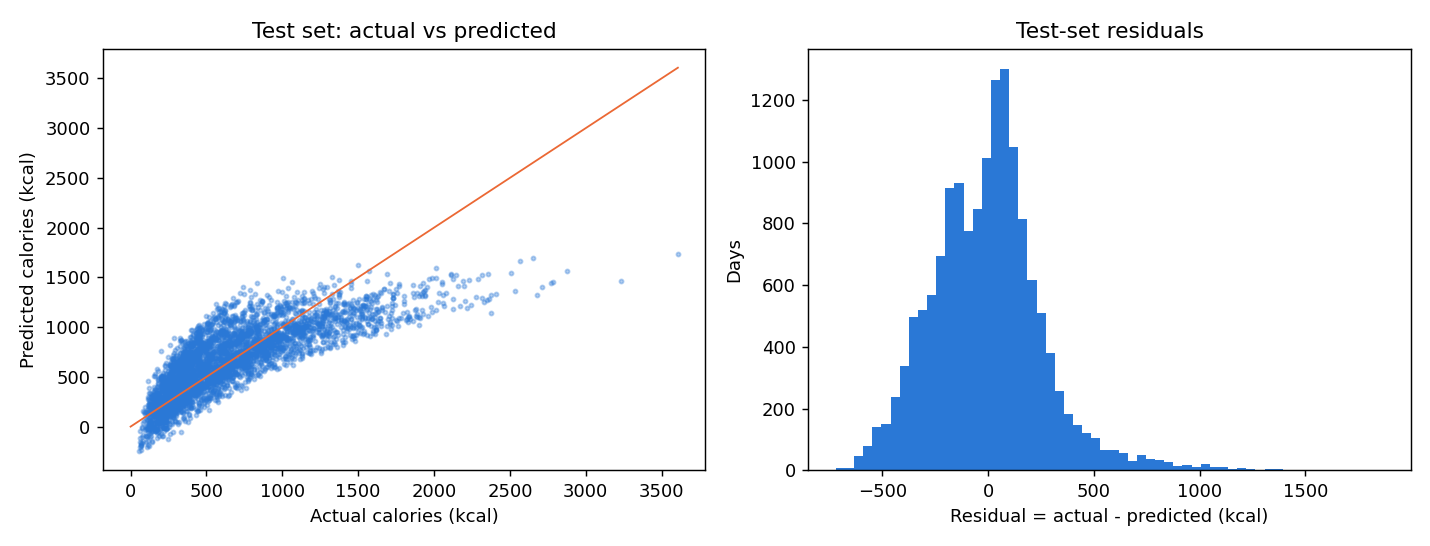

In [63]:
import json
import pandas as pd
from IPython.display import Image, display
cfg = json.loads((PROJECT_ROOT / "models/artifacts/calorie_linreg_config.json").read_text(encoding="utf-8"))
print("Storage mode used for this run :", cfg["storage_mode"].upper(), "|", cfg["silver_source"])
print("Rows  train / validation / test :", cfg["rows"])
print("Selected regParam              :", cfg["regParam"], "(chosen by validation RMSE)")
print("Features                       :", cfg["numeric_features"] + cfg["categorical_features"])
res = pd.read_csv(EVIDENCE / "regression_results.csv")
display(res.round(4))
display(pd.read_csv(EVIDENCE / "regression_tuning.csv").round(4))
display(pd.read_csv(EVIDENCE / "regression_coefficients.csv").round(4))
display(Image(filename=str(EVIDENCE / "regression_actual_vs_predicted.png")))

In [64]:
# Independent re-computation of the metrics from the saved predictions (scripts/test_analytics.py was executed separately)
v = json.loads((EVIDENCE / "analytics_validation.json").read_text(encoding="utf-8"))
print(f"analytics validation run {v['timestamp']}: {v['passed']}/{v['total']} checks passed")
for c in v["checks"]:
    print(("PASS " if c["passed"] else "FAIL "), c["check"], "-", c["detail"][:100])

analytics validation run 2026-10-11 14:21:19: 14/14 checks passed
PASS  prediction file covers every Silver row - 100,122 rows
PASS  serving formula == Spark MLlib predictions (max |diff| < 0.01 kcal; Spark file is rounded to 0.01) - max diff 0.00500
PASS  actual_calories column equals Silver calories_burned - 
PASS  test MAE recomputed independently == Spark's - 199.713 vs 199.713
PASS  test RMSE recomputed independently == Spark's - 263.644 vs 263.644
PASS  test R2 recomputed independently == Spark's - 0.6296 vs 0.6296
PASS  baseline (train mean) MAE recomputed == reported - 334.510 vs 334.510
PASS  model beats the baseline on test MAE - 199.7 < 334.5
PASS  no leakage columns among features - 
PASS  nearest-centroid assignment reproduces Spark cluster for every user - 437/437
PASS  monthly summary day counts add up - 230 == 230
PASS  monthly avg steps matches pandas groupby - 
PASS  fitness score within 0..100 and weights sum to 1 - 84.0
PASS  probability bands: high -> On track, mid

**Interpretation.** On held-out test days the model's MAE is about 200 kcal and RMSE about 264 kcal, R-squared 0.63, against an MAE of about 335 kcal
for always predicting the training mean (R-squared 0). The model therefore explains roughly 63% of the day-to-day variation in calories. It is a
moderate estimator. Limits: `steps` and `distance_km` are strongly correlated (r = 0.94), so their individual coefficients have opposite signs and should
not be read one by one; the dataset is partly simulated (REPORT section 2.5 notes implausible weight changes); the chronological check scores lower (R-squared 0.58),
which shows the relationship drifts through the year. The R-squared of 0.63 is a measured value, not a target we tuned toward.

## 13. REPORT-aligned Random Forest and K-Means (Spark MLlib)

The report (sections 2-3) describes experiments that differ from the ones in sections 5-7 of this notebook. Both are now implemented and measured:

| | Notebook (sections 5-7) | **REPORT-aligned** (this section) | Dashboard model |
|---|---|---|---|
| Classifier target | next-day achievement of the *personalised* goal (1.10 x own average) | **same-day `steps >= 8,000`** | next-day personalised goal |
| Algorithm | Random Forest (Spark MLlib) | **Random Forest (Spark MLlib)** | **Logistic Regression** (scikit-learn, `models/train_goal_achievement.py`) |
| Features | lag / rolling features | **15 numeric + 3 categorical same-day features (steps, distance excluded)** | lag / rolling features |
| Split | seeded hash 70/15/15 | **`randomSplit([.7,.15,.15], seed=42)`** | chronological (cutoff 2024-10-15) |
| K-Means unit | 100,122 user-**days**, K = 2..6 | **437 users** (per-user averages), K = 2..10 | - |

Scripts: `models/spark_report_classification.py`, `models/spark_report_kmeans.py`; outputs in `faculty_evidence/report_aligned/`; both read Silver from HDFS.

In [65]:
RA = EVIDENCE / "report_aligned"
info = json.loads((RA / "rf_run_info.json").read_text())
print("Report-aligned Random Forest | storage:", info["storage_mode"].upper(), "|", info["silver_source"])
print(f"records {info['records']:,}; share meeting the 8,000-step goal {info['positive_share']:.4f}; selected numTrees={info['numTrees']}, maxDepth={info['maxDepth']}")
display(pd.read_csv(RA / "rf_split_sizes.csv"))
grid = pd.read_csv(RA / "rf_tuning_grid.csv")
display(grid)
display(pd.read_csv(RA / "rf_metrics.csv").round(4))
display(pd.read_csv(RA / "rf_confusion_matrix.csv", index_col=0))
display(pd.read_csv(RA / "rf_feature_importance.csv").head(8).round(4))
display(pd.read_csv(RA / "rf_extra_checks.csv"))

Report-aligned Random Forest | storage: HDFS | hdfs://localhost:9000/fitpulse/silver
records 100,122; share meeting the 8,000-step goal 0.6134; selected numTrees=50, maxDepth=15


,Set,Records
0,Training,70383
1,Validation,14943
2,Test,14796


,numTrees,maxDepth,validation_ROC_AUC,seconds,status
0,50,5,0.726917,23.1,ok
1,50,10,0.749249,30.2,ok
2,50,15,0.754868,113.4,ok
3,50,20,0.754136,340.0,ok
4,100,5,0.729422,17.7,ok
5,100,10,0.754385,59.5,ok
6,100,15,NaN,0.0,NOT RUN: OutOfMemoryError (JVM heap) in the fi...
7,100,20,NaN,0.0,NOT RUN: OutOfMemoryError (JVM heap) in the fi...


,Metric,Test,Validation
0,Accuracy,0.7352,0.7293
1,Baseline accuracy (always majority class),0.6144,0.6096
2,F1 (goal-achieved class),0.7862,0.7809
3,F1 (weighted),0.7346,0.7282
4,Precision (goal-achieved class),0.7801,0.7708
5,Precision (weighted),0.7341,0.7275
6,ROC AUC,0.7585,0.7549
7,Recall (goal-achieved class),0.7923,0.7912
8,Recall (weighted),0.7352,0.7293


,Predicted 0,Predicted 1
Actual 0 (not achieved),3676,2030
Actual 1 (achieved),1888,7202


,feature,importance
0,weight_kg,0.2822
1,bmi,0.0929
2,height_cm,0.0601
3,activity_type_idx,0.0586
4,active_minutes,0.0480
5,calories_burned,0.0470
6,sleep_quality_score,0.0443
7,hydration_level,0.0432


,Check,Value
0,RF with steps + distance_km included (leakage ...,0.989524
1,"User-held-out (15% of users unseen), accuracy",0.723201
2,"User-held-out, ROC AUC",0.749823
3,User-held-out: users in held-out set,53.000000


**Interpretation and comparison with the report's printed numbers** (the report's values came from scikit-learn):

| Quantity | Report | Measured here (Spark MLlib) | Reading |
|---|---|---|---|
| Test accuracy | 0.7303 | 0.7352 | same level |
| Test ROC AUC | 0.7580 | 0.7585 | same level |
| Always-majority baseline | 0.6114 | 0.6144 | same |
| Goal-achieved precision / recall | 0.7751 / 0.7875 | 0.7801 / 0.7923 | same level |
| Top feature | weight_kg 0.2446 | weight_kg 0.2822 | same top feature, as the report says it proxies time of year |
| User-held-out accuracy / AUC | 0.725 / 0.755 | 0.723 / 0.750 | confirmed |
| Leakage demo (steps + distance included) | "100% accuracy" | 98.95% | confirmed (the report's "100%" should read "about 99%") |
| Best hyper-parameters | numTrees 100, maxDepth 20 (val AUC 0.759) | numTrees 50, maxDepth 15 (val AUC 0.7549) | **not reproduced**: (100 trees, depth 15) and (100, 20) crashed the JVM with `OutOfMemoryError` on this laptop (3 GB driver), see the grid above and `log_report_rf_hdfs_attempt1_full_grid.txt`; the other 6 of 8 grid points were measured |
| Split sizes | 70,084 / 15,019 / 15,019 | 70,383 / 14,943 / 14,796 | Spark `randomSplit` differs from scikit-learn's split |

,K,WCSS,Silhouette
0,2,2335.2238,0.3413
1,3,2079.4839,0.2754
2,4,1884.7713,0.2453
3,5,1708.5672,0.2507
4,6,1641.2755,0.2251
5,7,1538.0697,0.2443
6,8,1451.4081,0.2380
7,9,1368.4300,0.2595
8,10,1330.6722,0.2499


,cluster,Users,AvgSteps,AvgActiveMin,AvgSedentaryMin,AvgCalories,AvgHeartRate,AvgSleep,AvgIntensity,Segment label (from measured AvgActiveMin rank)
0,0,228,8620.72,71.09,944.61,674.96,131.26,424.30,0.07,Highest active-time
1,1,209,8630.54,68.68,950.10,647.32,130.38,421.23,0.07,Lowest active-time


,feature,min,max
0,AvgSteps,8250.78,8964.52
1,AvgActiveMin,64.59,74.68
2,AvgSedentaryMin,936.71,960.33
3,AvgCalories,436.73,1059.24
4,AvgHeartRate,113.13,150.07
5,AvgSleep,410.94,432.03
6,AvgIntensity,0.06,0.07


Why Spark's silhouette (0.3413 at K=2) differs from the report's 0.2018:
 K  sklearn_WCSS  sklearn_silhouette_euclidean  sklearn_silhouette_squared_euclidean
 2     2335.1849                        0.2018                                0.3413
 3     2052.6693                        0.1609                                0.2745
 4     1845.8082                        0.1554                                0.2662
 5     1706.6066                        0.1515                                0.2559
 6     1613.2629                        0.1429                                0.2408
 7     1524.4707                        0.1485                                0.2504
 8     1437.9954                        0.1456                                0.2454
 9     1371.3634                        0.1498                                0.2516
10     1305.7740                        0.1546                                0.2614

Spark's selected K=2 assignment scored with scikit-learn: euclidean silhouet

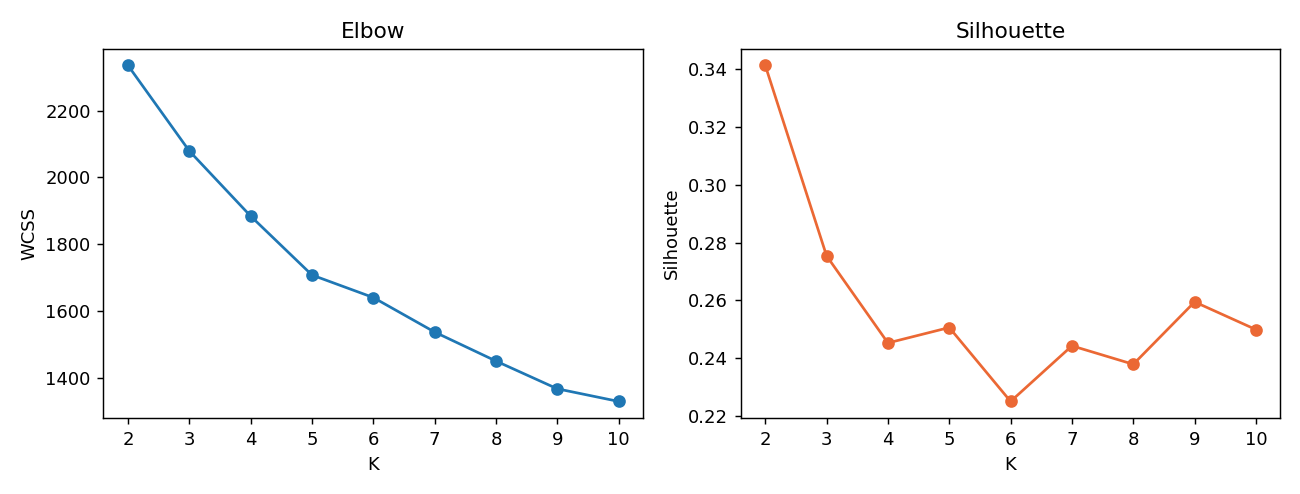

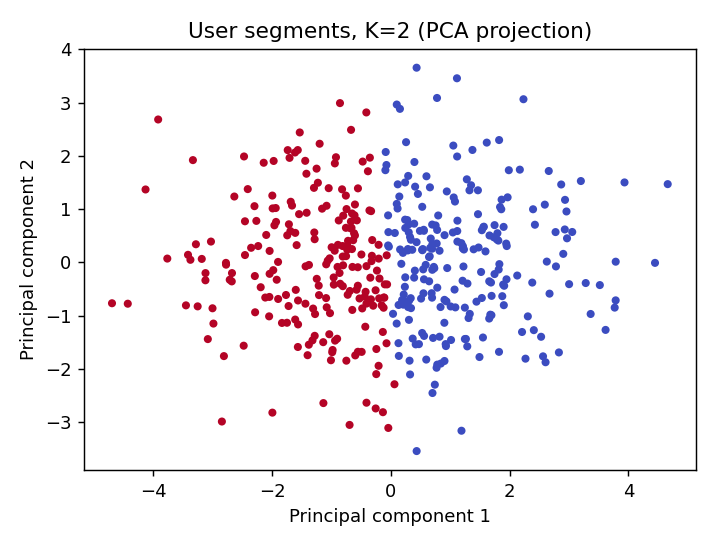

In [66]:
kev = pd.read_csv(RA / "kmeans_evaluation.csv")
display(kev.round(4))
display(pd.read_csv(RA / "kmeans_cluster_summary.csv"))
display(pd.read_csv(RA / "kmeans_user_range.csv").round(2))
print("Why Spark's silhouette (0.3413 at K=2) differs from the report's 0.2018:")
print((RA / "kmeans_silhouette_definition_check.txt").read_text(encoding="utf-8"))
display(Image(filename=str(RA / "kmeans_elbow_silhouette.png")))
display(Image(filename=str(RA / "kmeans_pca.png")))

**Interpretation.** K = 2 has the highest silhouette on the 437 user vectors (K = 2..10 evaluated), giving two groups of 209 and 228 users. The group labels come from the
*measured* average active minutes (68.7 vs 71.1), not from an assumed Sedentary / Moderate / Active scheme: the two segments differ by only about 2.4 active minutes,
5.5 sedentary minutes and 28 kcal, and average steps are the same (8,631 vs 8,621), so the report's honest conclusion stands.
**The 0.3413 vs 0.2018 difference is explained, not a discrepancy in the model:** Spark's `ClusteringEvaluator(distanceMeasure="squaredEuclidean")` and scikit-learn's Euclidean silhouette are
different definitions. Scoring the same Spark assignment with scikit-learn's Euclidean silhouette gives 0.2018, and scikit-learn reproduces the report's values for every K from 2 to 10.
The report's WCSS is 0.2% higher than Spark's because scikit-learn standardises with the population standard deviation (n) and Spark with the sample standard deviation (n-1).
The report text should therefore say *Euclidean silhouette (scikit-learn) 0.2018*, or quote Spark's squared-Euclidean 0.3413; it currently attributes 0.2018 to Spark's ClusteringEvaluator.

## 14. Dashboards (Power BI is the primary dashboard) and faculty-proof checklist

**Power BI** - `powerbi/FitPulse_PowerBI_Dashboard.pbix`, saved by Power BI Desktop 2.158 from a generated Power BI Project (`powerbi/build_powerbi.py`).
Five pages: Fitness Overview, Activity and Sleep, Calorie Prediction, User Segmentation, Model Evaluation (70 visuals, 34 DAX measures). It imports validated **CSV exports** of the Silver data and the saved
model results; it does **not** read HDFS (single node, replication factor 1). The five experiments (E1-E5) are shown one at a time and never combined.
Verified in Desktop: the `.pbix` reopens with data cached; card values equal independent pandas values; the Activity type slicer (Cycling) changes the cards to the expected values.
Not verified: the other slicers individually, cross-page behaviour. Full record: `faculty_evidence/powerbi/POWERBI_VALIDATION.md`.

**Streamlit** (`dashboard/app.py`) is the earlier per-user dashboard, kept as a **legacy/optional** component. It was tested with Streamlit's AppTest (below); that testing found and fixed a Windows crash
(`strftime('%-d')`). Its data source is the local SQLite database, not HDFS.

Power BI file: powerbi\FitPulse_PowerBI_Dashboard.pbix | exists: True | size: 4,508,752 bytes
project_validation: 70/70 automated checks passed
dashboard/dashboard_validation: 15/15 automated checks passed

# PBIX structure check
File: `D:\bigdata\fitpulsee\FitPulse\powerbi\FitPulse_PowerBI_Dashboard.pbix`

| Check | Result | Detail |
|---|---|---|
| PBIX package opens as a zip | PASS | 87 entries, 4,403 KB |
| contains a data model | PASS | ['DataModel'] |
| contains a report definition (Layout or PBIR) | PASS | PBIR |
| page count | PASS | ['Fitness Overview', 'Activity and Sleep', 'Calorie Prediction', 'User Segmentation', 'Model Evaluation'] |
| page exists: Fitness Overview | PASS |  |
| page exists: Activity and Sleep | PASS |  |
| page exists: Calorie Prediction | PASS |  |
| page exists: User Segmentation | PASS |  |
| page exists: Model Evaluation | PASS |  |
| visuals found | PASS | 70 visuals |
| slicers present | PASS | 15 slicers |
| no visual references a nonexistent colu

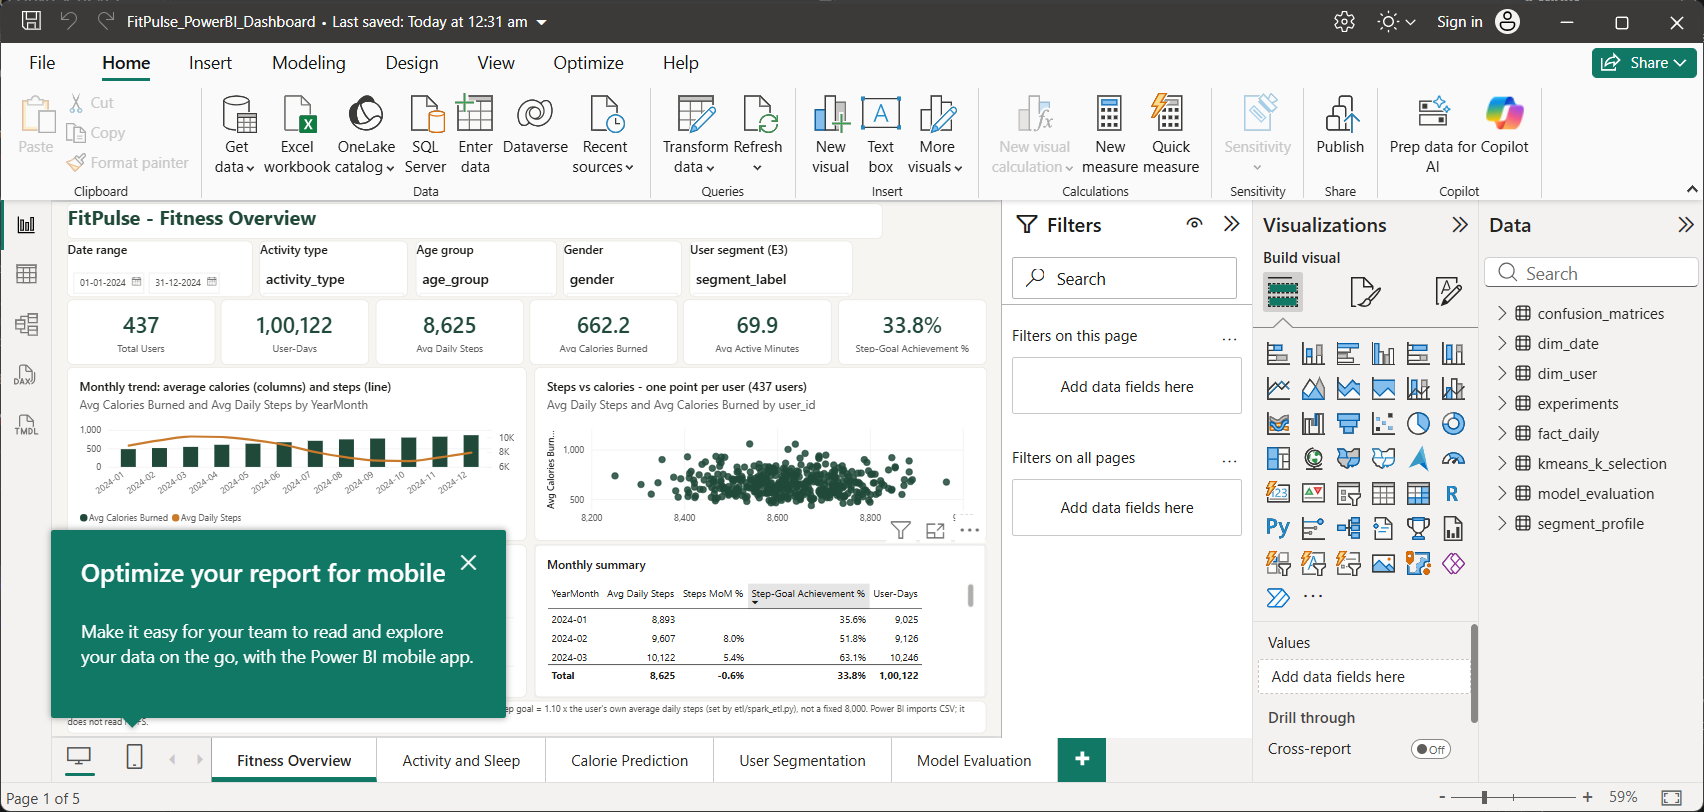

1b_slicer_Cycling_selected.png


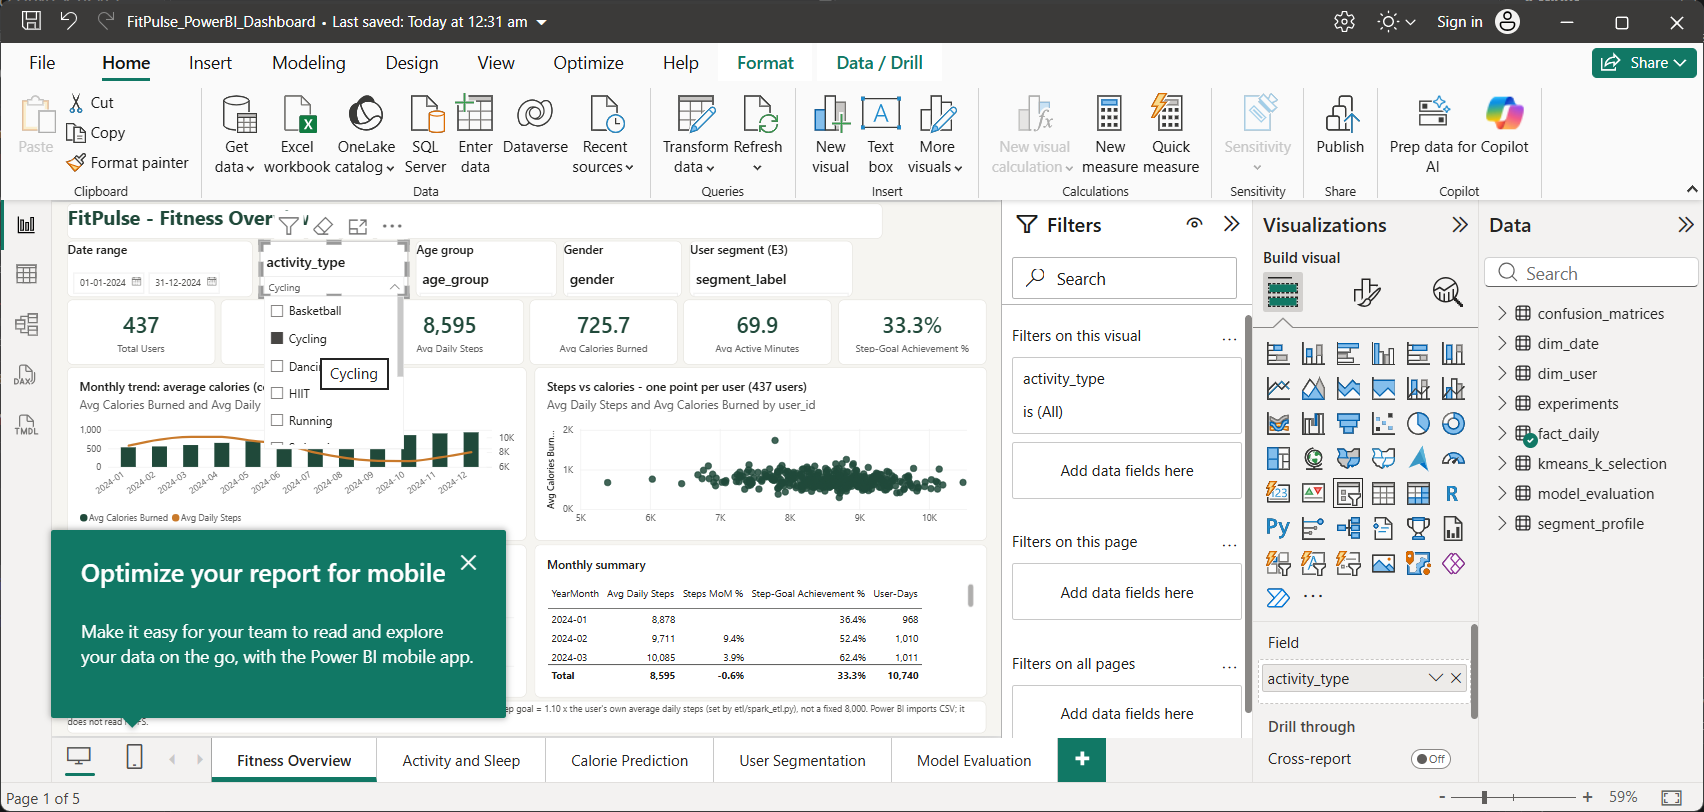

2_Activity_and_Sleep.png


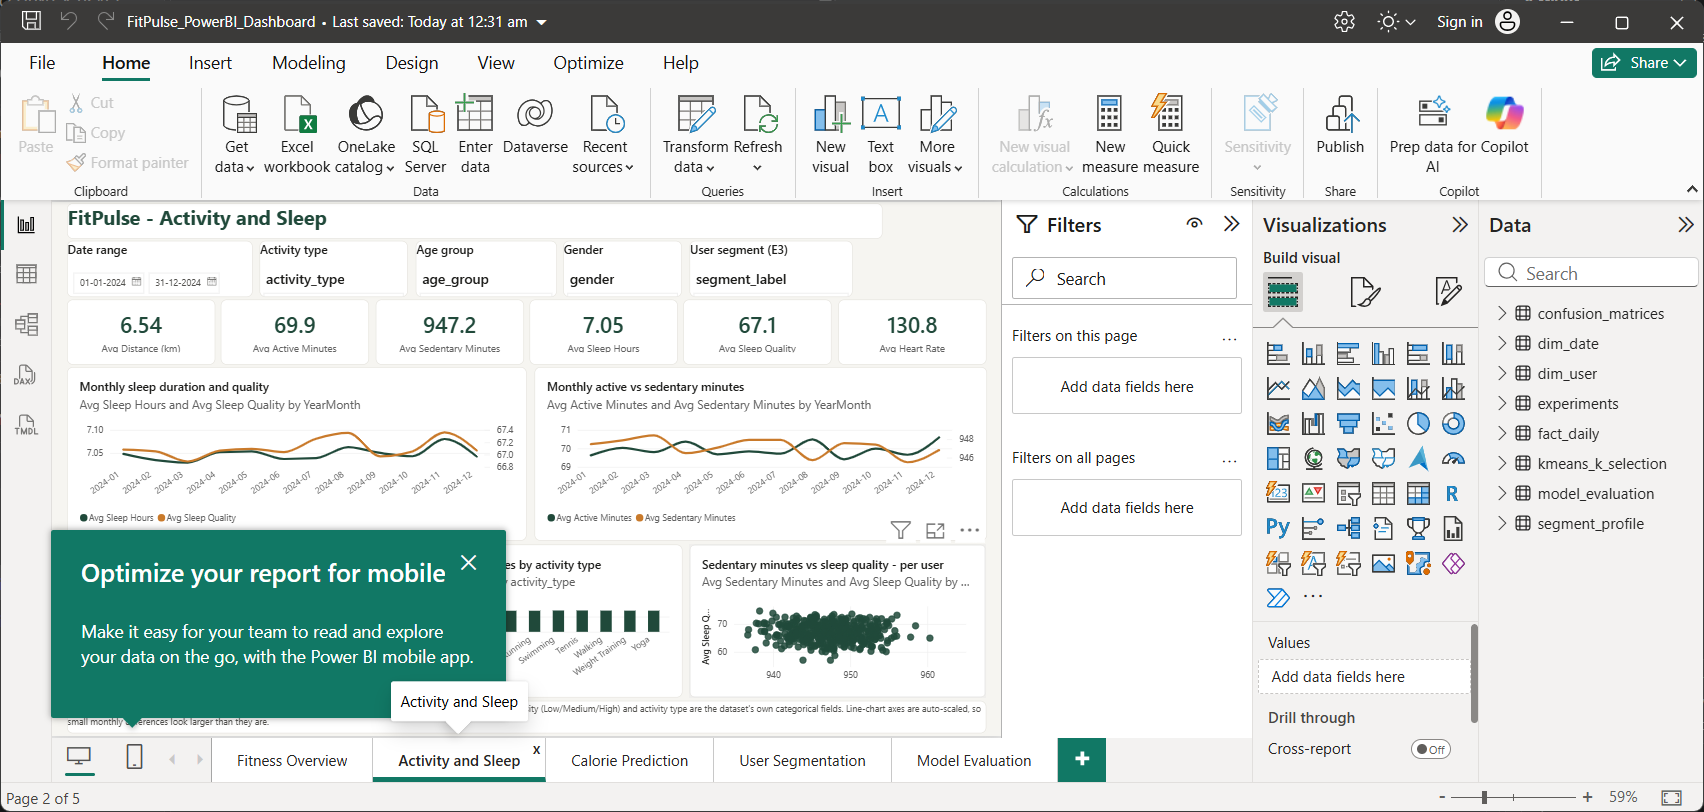

3_Calorie_Prediction.png


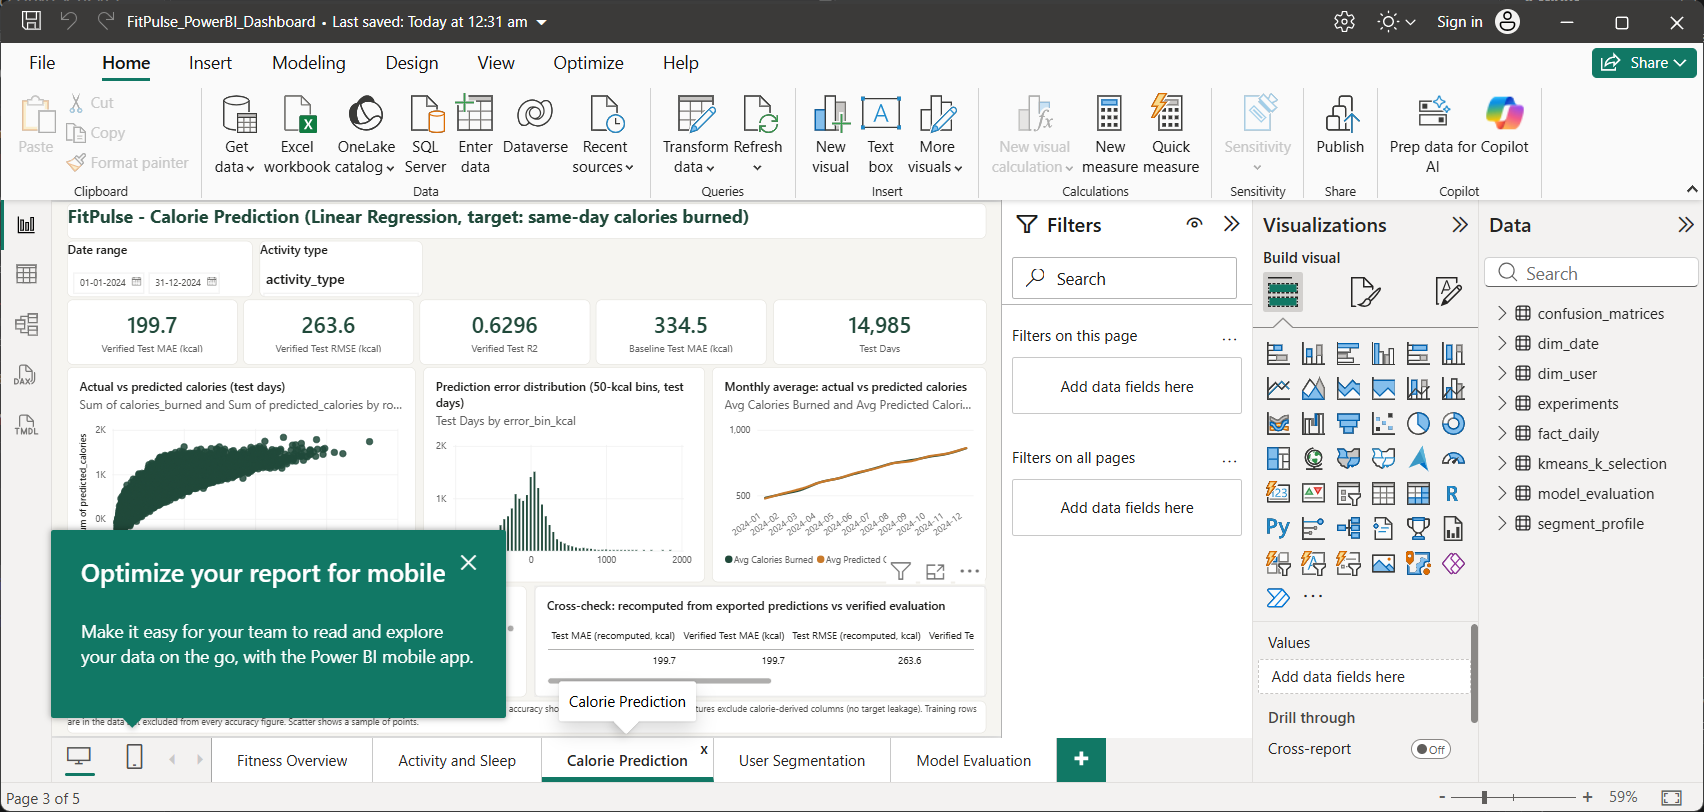

4_User_Segmentation.png


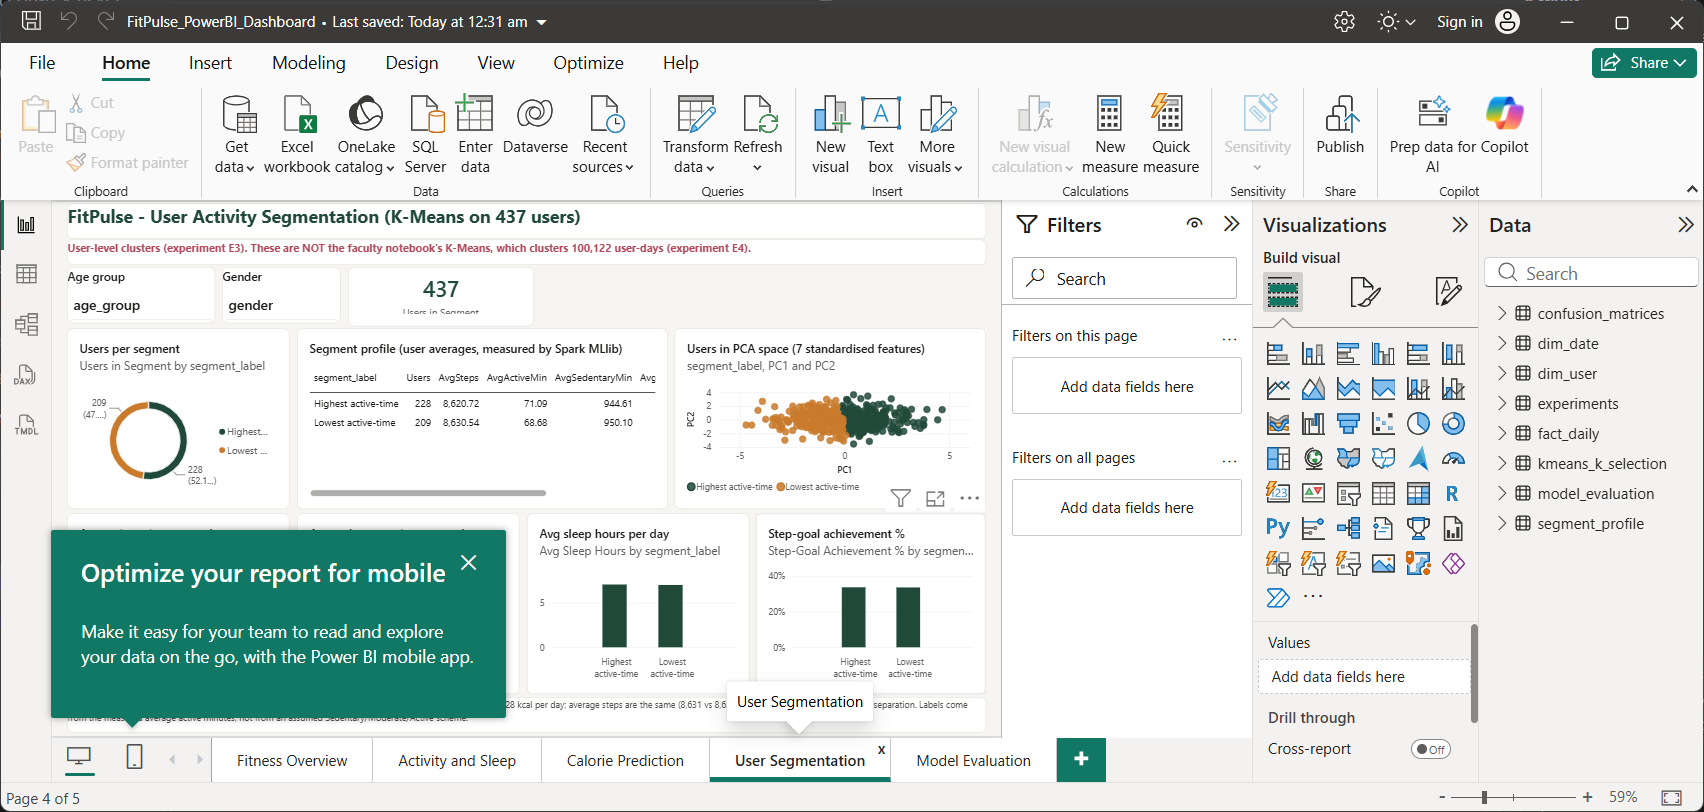

5_Model_Evaluation.png


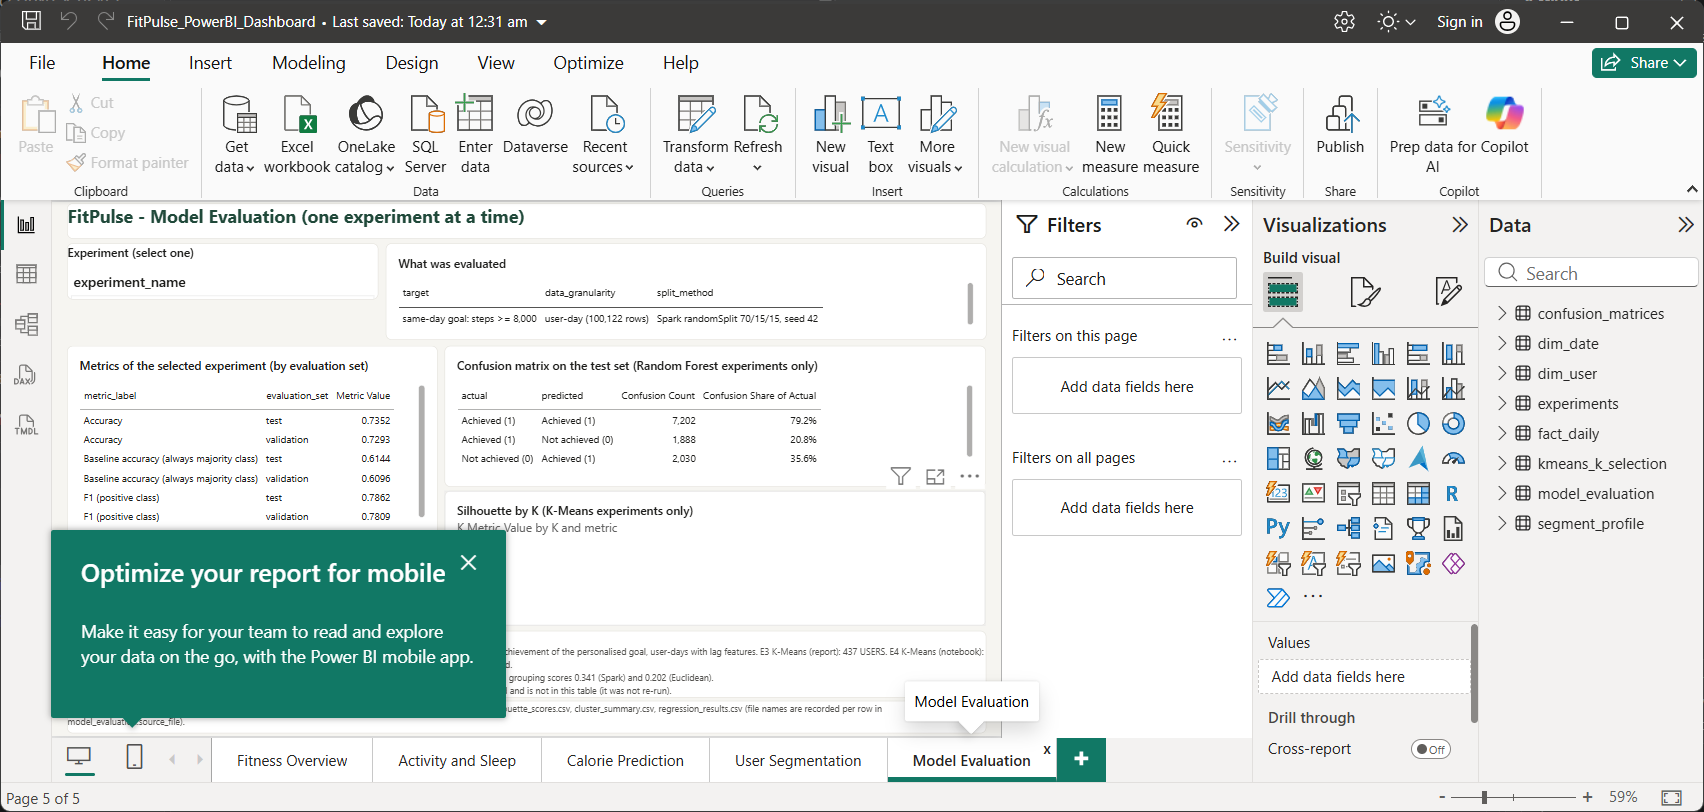

In [67]:
import json
from IPython.display import Image, display
pbix = PROJECT_ROOT / "powerbi" / "FitPulse_PowerBI_Dashboard.pbix"
print("Power BI file:", pbix.relative_to(PROJECT_ROOT), "| exists:", pbix.exists(), "| size: %s bytes" % (f"{pbix.stat().st_size:,}" if pbix.exists() else "n/a"))
for name in ("project_validation", "dashboard/dashboard_validation"):
    f = EVIDENCE / ("powerbi/" + name + ".json" if name == "project_validation" else name + ".json")
    d = json.loads(f.read_text(encoding="utf-8"))
    print(f"{name}: {d['passed']}/{d['total']} automated checks passed")
print()
print((EVIDENCE / "powerbi" / "pbix_structure_check.md").read_text(encoding="utf-8")[:1500])
shots = sorted((EVIDENCE / "powerbi" / "pbix_screenshots").glob("*.png"))
print("Real screenshots of the opened .pbix in Power BI Desktop:", [s.name for s in shots])
for s in shots:
    print(s.name)
    display(Image(filename=str(s), width=900))

In [68]:
mm = pd.read_csv(EVIDENCE / "model_metrics.csv")
print("faculty_evidence/model_metrics.csv - every row carries its source file; rows:", len(mm))
display(mm[mm.metric.isin(["Accuracy", "ROC AUC", "ROC-AUC", "F1 (goal-achieved class)", "MAE (kcal)", "RMSE (kcal)", "R2"])]
        .drop(columns=["source_file"]).round(4).reset_index(drop=True))
print("\nKnown limits: RF experiments differ between notebook and report (section 13); the legacy Streamlit app's classifier is Logistic Regression "
      "(ROC-AUC 0.755 from models/metrics_report.md, an earlier training run that was not repeated); HDFS is single node; Power BI imports CSV and does not read HDFS.")

faculty_evidence/model_metrics.csv - every row carries its source file; rows: 69


,model,experiment,set,metric,value
0,Random Forest (Spark MLlib),notebook: next-day personalised goal [local Pa...,test,Accuracy,0.7187
1,Random Forest (Spark MLlib),notebook: next-day personalised goal [local Pa...,test,ROC-AUC,0.8247
2,Random Forest (Spark MLlib),notebook: next-day personalised goal [HDFS re-...,test,Accuracy,0.7187
3,Random Forest (Spark MLlib),notebook: next-day personalised goal [HDFS re-...,test,ROC-AUC,0.8247
4,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,validation,Accuracy,0.7293
5,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,test,Accuracy,0.7352
6,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,validation,F1 (goal-achieved class),0.7809
7,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,test,F1 (goal-achieved class),0.7862
8,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,validation,ROC AUC,0.7549
9,Random Forest (Spark MLlib),REPORT-aligned: same-day steps >= 8000,test,ROC AUC,0.7585



Known limits: RF experiments differ between notebook and report (section 13); the legacy Streamlit app's classifier is Logistic Regression (ROC-AUC 0.755 from models/metrics_report.md, an earlier training run that was not repeated); HDFS is single node; Power BI imports CSV and does not read HDFS.


In [55]:
spark.stop()
print("Spark session stopped. Evidence files:")
for f in sorted(EVIDENCE.iterdir()):
    print("  ", f.name)

Spark session stopped. Evidence files:
   build_notebook.py
   classification_results.csv
   classification_split_comparison.csv
   cluster_profile_heatmap.png
   cluster_sizes.png
   cluster_summary.csv
   confusion_matrix.csv
   confusion_matrix.png
   dataset_summary.csv
   duplicate_analysis.csv
   final_feature_set.csv
   log_prepare_raw_dataset.txt
   log_spark_etl.txt
   missing_values_bronze.csv
   missing_values_silver.csv
   missing_values_source.csv
   preprocessing_summary.csv
   REPORT_VALUES.md
   rf_feature_importance.csv
   rf_feature_importance.png
   rf_test_predictions.csv
   rf_validation_tuning.csv
   schemas.txt
   silhouette_scores.csv
   silhouette_scores.png
   spark_hdfs_evidence.txt
   split_summary.csv
   statistical_summary.csv
   user_cluster_mix.csv
